# AISE 4010: Air-quality forecasting, Stages 1-3

 <h1 style="text-align: center;">AIR-QUALITY FORECASTING</h1>

Forecast the next six hourly benzene concentrations (`C6H6(GT)`, micrograms/m³)
from the preceding 72 hourly observations of seven lagged variables from UCI Air Quality (Italy).
At forecast origin t, inputs end at t and the six outputs correspond to t+1 through t+6.
This is retrospective forecasting with hourly measurement availability assumed; it is not a
certified pollution alarm. No future observed weather or sensor response is supplied.

Stages 1 and 2 preserve the original development sequence. Stage 3 adds a Transformer,
a common-protocol refit comparison, bounded validation-only HPO, a locked final test,
frequency/failure/reliability analysis, and reproducibility evidence.

In [1]:
# IMPORTS:

import sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import sklearn
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import time
import random
from copy import deepcopy
import copy
from itertools import product
import torch.nn.functional as F

from IPython.display import display, Markdown
from pathlib import Path

<h2 style="text-align: center;">STAGE 1: Data, Baselines, MLP</h1>

In [2]:
# S1-DATA: relative paths only; download instructions are in data/README.md.
DATA_CANDIDATES = [Path('data/AirQualityUCI.csv'), Path('AirQualityUCI.csv'),
                   Path('../data/AirQualityUCI.csv'), Path('../4010Project/AirQualityUCI.csv')]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place AirQualityUCI.csv in data/ next to this notebook. See data/README.md.')
df = pd.read_csv(DATA_PATH, sep=';', decimal=',')
display(df.head())

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [3]:
# The CSV includes extra unnamed columns caused by trailing separators. We remove those columns because they contain no useful measurements.
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

In [4]:
# 2. Chronological order:

# Create a chronological datetime index by combine the Date and Time columns before splitting, and removed rows with invalid timestamps.
df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce",
)
df = df.dropna(subset=["DateTime"]).set_index("DateTime").sort_index()
df = df.drop(columns=["Date", "Time"])

print(f"Rows after removing invalid timestamps: {len(df)}")
print(f"Time span: {df.index.min()} to {df.index.max()}")
print(f"Chronological order: {df.index.is_monotonic_increasing}")

assert df.index.is_unique, "Resolve duplicate timestamps explicitly before modelling."
assert (df.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(),     "Non-hourly gaps found: reindex hourly and rerun the entire protocol; do not bridge gaps silently."
print("Resampling rule: none; exact hourly timestamp grid verified.")

Rows after removing invalid timestamps: 9357
Time span: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Chronological order: True
Resampling rule: none; exact hourly timestamp grid verified.


In [5]:
# 3. Chronological splitting:

# Chronological 60/20/20 splitting because our goal is to predict future measurements from past observations.
# We also split before fitting imputation to prevent data leakage or scaling steps so their statistics can be calculated from training data only.
train_size = int(len(df) * 0.6)
val_size = int(len(df) * 0.2)

train_df = df.iloc[:train_size].copy()
val_df = df.iloc[train_size:train_size + val_size].copy()
test_df = df.iloc[train_size + val_size:].copy()

print(f"Train shape: {train_df.shape}")
print(f"Validation shape: {val_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Train ends: {train_df.index[-1]}")
print(f"Validation ends: {val_df.index[-1]}")
print(f"Test starts: {test_df.index[0]}")

print("Chronological split created: training precedes validation, which precedes test.")

Train shape: (5614, 13)
Validation shape: (1871, 13)
Test shape: (1872, 13)
Train ends: 2004-10-30 15:00:00
Validation ends: 2005-01-16 14:00:00
Test starts: 2005-01-16 15:00:00
Chronological split created: training precedes validation, which precedes test.


In [6]:
# 4. Handle missing values:

# -200 represents a missing measurement. We replace those values with NaN so they are not treated as real sensor readings.
train_missing = train_df.replace(-200, np.nan)
val_missing = val_df.replace(-200, np.nan)
test_missing = test_df.replace(-200, np.nan)

missing_summary = pd.DataFrame({
    "Train missing (%)": train_missing.isna().mean() * 100,
    "Validation missing (%)": val_missing.isna().mean() * 100,
    "Test missing (%)": test_missing.isna().mean() * 100,
}).round(2)
display(missing_summary.sort_values("Train missing (%)", ascending=False))

,Train missing (%),Validation missing (%),Test missing (%)
NMHC(GT),83.72,100.00,100.00
CO(GT),25.61,8.23,4.86
NO2(GT),24.62,10.80,3.10
NOx(GT),24.56,10.80,3.10
PT08.S1(CO),2.64,7.06,4.59
PT08.S2(NMHC),2.64,7.06,4.59
C6H6(GT),2.64,7.06,4.59
PT08.S3(NOx),2.64,7.06,4.59
PT08.S4(NO2),2.64,7.06,4.59
PT08.S5(O3),2.64,7.06,4.59


In [7]:
# Feature set is predeclared; NMHC(GT) is not an input. No held-out missingness
# is used to select features. Its training missingness is documented for context.
columns_to_drop = ['NMHC(GT)']
print('NMHC(GT) training missing fraction:', train_missing['NMHC(GT)'].isna().mean())
train_missing = train_missing.drop(columns=columns_to_drop)
val_missing = val_missing.drop(columns=columns_to_drop)
test_missing = test_missing.drop(columns=columns_to_drop)

NMHC(GT) training missing fraction: 0.8371927324545778


In [8]:
# 6. Target and features selection:

# Benzene is the target variable.
TARGET_COL = "C6H6(GT)"
features = ["C6H6(GT)", "PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S5(O3)", "T", "RH", "AH"]
# Saving separate copies of the original benzene target values.
train_target_observed = train_missing[TARGET_COL].copy()
val_target_observed = val_missing[TARGET_COL].copy()

| Feature | Chemical / Parameter | Full Name |
|---|---|---|
| `C6H6(GT)` | C₆H₆ | Benzene (Ground Truth) |
| `PT08.S1(CO)` | CO | Carbon Monoxide |
| `PT08.S2(NMHC)` | NMHC | Non-Methane Hydrocarbons |
| `PT08.S5(O3)` | O₃ | Ozone |
| `T` | Temperature | Ambient Temperature (°C) |
| `RH` | Relative Humidity | Relative Humidity (%) |
| `AH` | Absolute Humidity | Absolute Humidity |

**Note:** The PT08 features represent sensor responses to specific
gases rather than their direct concentrations. These sensor readings
are used as input features to help predict the benzene concentration
(`C6H6(GT)`).

In [9]:
# 7. Handle missing values in features:

# We use forward-filling to replace missing values with the most recent available measurement.
# Forward-filling respects the chronological order of the data, and doesn't cause data leakage.
# The median of the training dataset is used as a fallback in the case where
# forward-filling cannot find a previous measurement (e.g., at the start of the dataset).

# Selecting the features from each set.
train_feature_raw = train_missing[features]
val_feature_raw = val_missing[features]
test_feature_raw = test_missing[features]
# Calculating the median using the training dataset only.
training_feature_medians = train_feature_raw.median()

# Defining the missing value imputation function.
def causal_impute_inputs(frame, fallback_values):
    return frame.ffill().fillna(fallback_values)

# Handle missing values in the features using forward-filling and median fallback.
train_processed = causal_impute_inputs(train_feature_raw, training_feature_medians)
val_processed = causal_impute_inputs(val_feature_raw, training_feature_medians)
test_processed = causal_impute_inputs(test_feature_raw, training_feature_medians)

print("Missing target observations retained for masking:", {
    "train": int(train_target_observed.isna().sum()),
    "validation": int(val_target_observed.isna().sum()),
})
print("Remaining missing input features:", {
    "train": int(train_processed.isna().sum().sum()),
    "validation": int(val_processed.isna().sum().sum()),
    "test": int(test_processed.isna().sum().sum()),
})

Missing target observations retained for masking: {'train': 148, 'validation': 132}
Remaining missing input features: {'train': 0, 'validation': 0, 'test': 0}


In [11]:
# 8. Scale inputs using training statistics; preserve observed target masks:

LOOKBACK = 72                               # Previous 72 hours as input
HORIZON = 6                                 # Predict the next HORIZON hours as output
STRIDE = 1                                  # Window step size: 1 hour => consecutive windows overlap heavily
target_idx = features.index(TARGET_COL)     # Finds position of Benzene within the features list

# Using StandardScaler to standardize the features.
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_processed[features])
val_scaled = scaler.transform(val_processed[features])
test_scaled = scaler.transform(test_processed[features])
# Extract target mean and scale for the target variable.
target_mean = scaler.mean_[target_idx]
target_scale = scaler.scale_[target_idx]

# Scale the target variable using the training statistics.
train_target_scaled = (train_target_observed.to_numpy() - target_mean) / target_scale
val_target_scaled = (val_target_observed.to_numpy() - target_mean) / target_scale


In [12]:
# 9. Create labeled windows for training and validation:

# Defining the function to create labeled windows.
# STRIDE < LOOKBACK guarantees consecutive windows overlap (stride 1 => they share LOOKBACK-1 hours of input).
assert STRIDE < LOOKBACK, "STRIDE must be smaller than LOOKBACK for overlapping windows"

def create_labeled_windows(input_data, target_data, lookback=LOOKBACK, horizon=HORIZON, stride=STRIDE):
    X, y, target_masks = [], [], []

    for start in range(0, len(input_data) - lookback - horizon + 1, stride):
        target_window = target_data[start + lookback : start + lookback + horizon]

        # Stores the previous LOOKBACK hours of input features.
        X.append(input_data[start : start + lookback])
        # Stores the benzene target values for the next HORIZON hours.
        y.append(target_window)
        # Identifies which target values are observed (not NaN) for masking during training.
        target_masks.append(np.isfinite(target_window))

    return np.asarray(X), np.asarray(y), np.asarray(target_masks)

# Each split is windowed independently; NaN targets remain masked, not imputed.
X_train, y_train, train_target_mask = create_labeled_windows(train_scaled, train_target_scaled)
X_val, y_val, val_target_mask = create_labeled_windows(val_scaled, val_target_scaled)

# Prepare test inputs only; do not create test labels or calculate test metrics in Stage 1.
X_test = np.asarray([
    test_scaled[start : start + LOOKBACK]
    for start in range(0, len(test_scaled) - LOOKBACK - HORIZON + 1, STRIDE)
])

print(f"Feature order: {features}")
print(f"Target: {TARGET_COL}; lookback: {LOOKBACK} hours; horizon: {HORIZON} hours")
print(f"Train: X={X_train.shape}, y={y_train.shape}; observed labels={int(train_target_mask.sum()):,}/{train_target_mask.size:,}")
print(f"Validation: X={X_val.shape}, y={y_val.shape}; observed labels={int(val_target_mask.sum()):,}/{val_target_mask.size:,}")
print(f"Test inputs prepared: X={X_test.shape}; test labels and metrics remain unused.")

# Overlap check: window t+1 should reuse the last (LOOKBACK - STRIDE) hours of window t's input.
overlap_hours = LOOKBACK - STRIDE
assert np.allclose(X_train[1][:overlap_hours], X_train[0][STRIDE:]), "Consecutive windows do not overlap as expected"
print(f"Windows overlap: consecutive windows share {overlap_hours} of {LOOKBACK} input hours (stride = {STRIDE} h).")

print("Training and validation windows created with masked missing target labels.")

Feature order: ['C6H6(GT)', 'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Target: C6H6(GT); lookback: 72 hours; horizon: 6 hours
Train: X=(5537, 72, 7), y=(5537, 6); observed labels=32,334/33,222
Validation: X=(1794, 72, 7), y=(1794, 6); observed labels=9,972/10,764
Test inputs prepared: X=(1795, 72, 7); test labels and metrics remain unused.
Windows overlap: consecutive windows share 71 of 72 input hours (stride = 1 h).
Training and validation windows created with masked missing target labels.


In [13]:
# 10. Dataset timestamp audit and exploratory figures.
time_deltas = df.index.to_series().diff().dropna()
native_interval = time_deltas.mode().iloc[0]
long_gaps = time_deltas[time_deltas > native_interval]

print(f"Rows: {len(df):,}")
print(f"Coverage: {df.index.min()} to {df.index.max()}")
print(f"Native sampling interval (mode): {native_interval}")
print(f"Duplicate timestamps: {int(df.index.duplicated().sum())}")
print(f"Intervals longer than the native interval: {len(long_gaps)}")
if not long_gaps.empty:
    print(f"Longest interval: {time_deltas.max()}")


Rows: 9,357
Coverage: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Native sampling interval (mode): 0 days 01:00:00
Duplicate timestamps: 0
Intervals longer than the native interval: 0


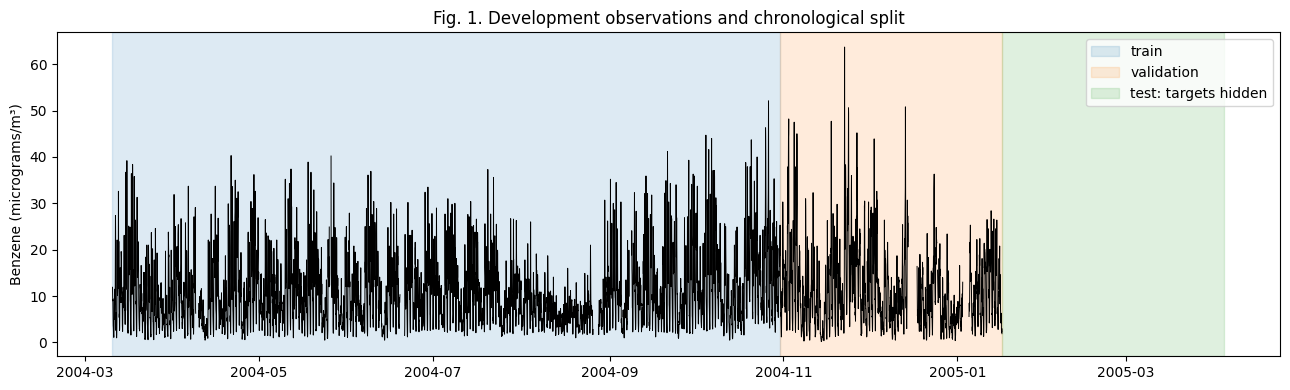

In [14]:
# Fig. 1. Development target series and chronological boundaries.
# Test targets are not plotted before the model is locked.
fig, ax = plt.subplots(figsize=(13, 4))
development = pd.concat([train_df, val_df])[TARGET_COL].replace(-200, np.nan)
ax.plot(development.index, development, lw=0.7, color='k')
for part, color, label in [(train_df, 'tab:blue', 'train'),
                           (val_df, 'tab:orange', 'validation'),
                           (test_df, 'tab:green', 'test: targets hidden')]:
    ax.axvspan(part.index.min(), part.index.max(), color=color, alpha=0.15, label=label)
ax.set_ylabel('Benzene (micrograms/m³)')
ax.set_title('Fig. 1. Development observations and chronological split')
ax.legend(); fig.tight_layout(); plt.show()

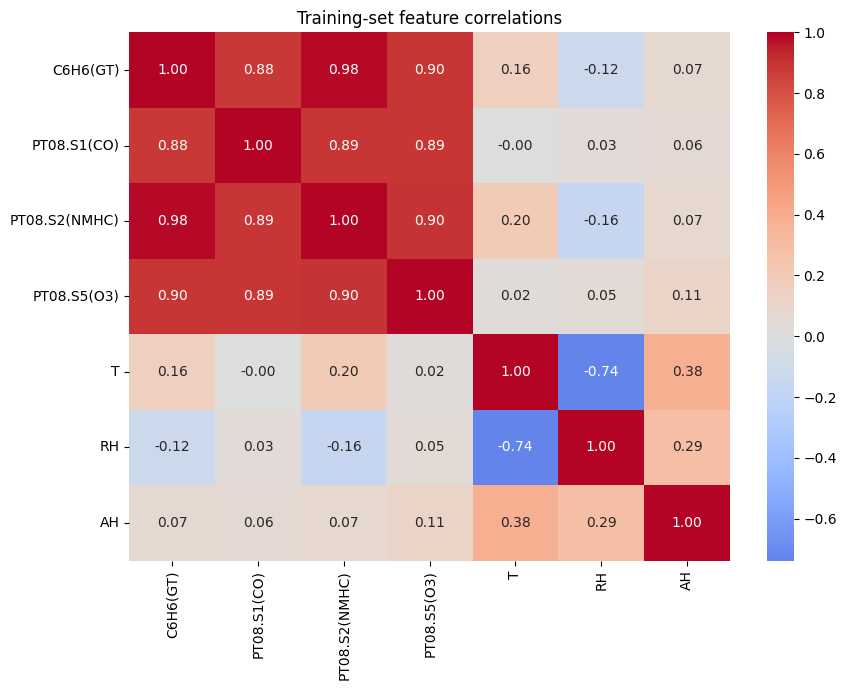

In [15]:
# Figure 2 — correlations calculated from training observations only
train_correlations = train_missing[features].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(train_correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Training-set feature correlations")
fig.tight_layout()
plt.show()

In [16]:
# 11. 6-hour pattern naive baseline — repeat the most recent HORIZON-hour target pattern:

# Using RMSE and MAE for evluation metrics.
# Accuracy and F1 are classification metrics, so not suitable in this case.

assert HORIZON <= LOOKBACK, "Baseline repeats the last HORIZON hours, so the lookback must cover at least HORIZON hours"
baseline_start = time.perf_counter()
baseline_pred_scaled = X_val[:, -HORIZON:, target_idx]
baseline_prediction_seconds = time.perf_counter() - baseline_start

# Undo target standardization so the reported errors are in the recorded units.
target_mean = scaler.mean_[target_idx]
target_scale = scaler.scale_[target_idx]
y_val_original = y_val * target_scale + target_mean
baseline_pred_original = baseline_pred_scaled * target_scale + target_mean

observed_val = val_target_mask
baseline_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], baseline_pred_original[observed_val]))
baseline_mae = mean_absolute_error(y_val_original[observed_val], baseline_pred_original[observed_val])

print("Baseline predictions and validation targets have shape:", baseline_pred_original.shape)
print(f"Metrics use only observed validation targets: {int(observed_val.sum()):,}/{observed_val.size:,} target values.")

Baseline predictions and validation targets have shape: (1794, 6)
Metrics use only observed validation targets: 9,972/10,764 target values.


In [17]:
# 12. MLP model — fully connected feedforward neural network:

# Setting random seeds for reproducibility.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training parameters for the MLP model.
batch_size = 64
epochs = 15
learning_rate = 0.001

# Prepare the training data loader with masked targets for the MLP model.
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(np.nan_to_num(y_train, nan=0.0), dtype=torch.float32),
        torch.tensor(train_target_mask, dtype=torch.float32),
    ),
    batch_size=batch_size,
    shuffle=True,
)

# Define the MLP model architecture.
class TimeSeriesMLP(nn.Module):
    def __init__(self, lookback, num_features, horizon):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(lookback * num_features, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, horizon),
        )

    def forward(self, x):
        return self.network(x)

mlp_model = TimeSeriesMLP(LOOKBACK, len(features), HORIZON).to(device)
mlp_parameter_count = sum(parameter.numel() for parameter in mlp_model.parameters() if parameter.requires_grad)

### MLP Architecture

| Layer | Operation | Output Size | Activation |
|---|---|---|---|
| Input | 72-hour input with 7 features | (72, 7) | — |
| Flatten | Converts input into a 1D vector | 504 | — |
| Fully Connected 1 | Dense layer with 128 neurons | 128 | ReLU |
| Dropout | Dropout rate of 0.2 | 128 | — |
| Fully Connected 2 | Dense layer with 64 neurons | 64 | ReLU |
| Output Layer | Dense layer with 6 neurons | 6 | — |

**Input:** 72 hours of air quality data with 7 features (504 total input values).

**Output:** 6 predicted benzene concentrations, representing the next 6 hours.

ReLU helps the MLP learn complex nonlinear patterns, while Dropout (0.2) helps prevent the model from overfitting those patterns to the training data.

Trained on 5537 training windows; evaluated on 1794 validation windows.


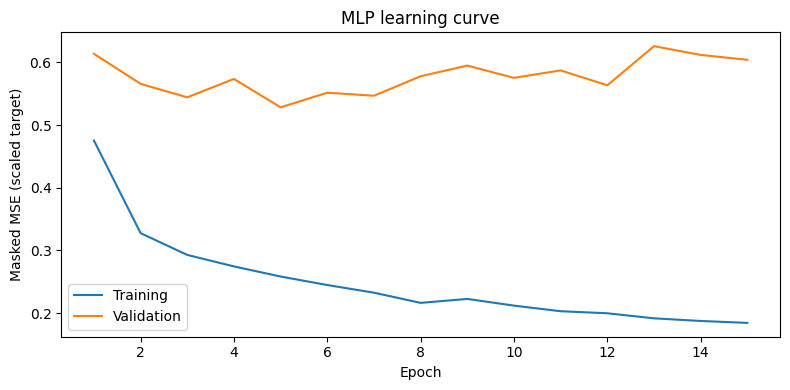

In [18]:
# Define a masked mean squared error loss function that ignores missing target values during training.
def masked_mse_loss(predictions, targets, target_mask):
    squared_errors = (predictions - targets).square() * target_mask
    return squared_errors.sum() / target_mask.sum().clamp_min(1.0)


criterion = masked_mse_loss
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=learning_rate)
mlp_training_losses, mlp_validation_losses = [], []
val_tensor = torch.tensor(X_val, dtype=torch.float32, device=device)
val_targets_tensor = torch.tensor(np.nan_to_num(y_val, nan=0.0), dtype=torch.float32, device=device)
val_mask_tensor = torch.tensor(val_target_mask, dtype=torch.float32, device=device)

# Only training batches contribute gradients or optimizer updates.
mlp_training_start = time.perf_counter()
for epoch in range(epochs):
    mlp_model.train()
    epoch_loss_sum, epoch_target_count = 0.0, 0
    for batch_x, batch_y, batch_mask in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        batch_mask = batch_mask.to(device)

        optimizer.zero_grad()
        predictions = mlp_model(batch_x)
        loss = criterion(predictions, batch_y, batch_mask)
        loss.backward()
        optimizer.step()
        observed_count = int(batch_mask.sum().item())
        epoch_loss_sum += loss.item() * observed_count
        epoch_target_count += observed_count

    mlp_training_losses.append(epoch_loss_sum / epoch_target_count)
    mlp_model.eval()
    with torch.no_grad():
        val_predictions = mlp_model(val_tensor)
        mlp_validation_losses.append(
            criterion(val_predictions, val_targets_tensor, val_mask_tensor).item()
        )
mlp_training_seconds = time.perf_counter() - mlp_training_start

# Validation is evaluation-only; it does not update model parameters.
mlp_model.eval()
validation_start = time.perf_counter()
with torch.no_grad():
    mlp_pred_scaled = mlp_model(val_tensor).cpu().numpy()
mlp_prediction_seconds = time.perf_counter() - validation_start

mlp_pred_original = mlp_pred_scaled * target_scale + target_mean
mlp_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], mlp_pred_original[observed_val]))
mlp_mae = mean_absolute_error(y_val_original[observed_val], mlp_pred_original[observed_val])

print(f"Trained on {len(X_train)} training windows; evaluated on {len(X_val)} validation windows.")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), mlp_training_losses, label="Training")
plt.plot(range(1, epochs + 1), mlp_validation_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE (scaled target)")
plt.title("MLP learning curve")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# 13. 1D CNN model — convolutional neural network for time series:

# Reset the seed so this model's initialization and batch order are reproducible.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Define the 1D CNN model architecture.
class TimeSeriesCNN(nn.Module):
    def __init__(self, num_features, horizon):
        super().__init__()
        self.conv1 = nn.Conv1d(
            in_channels=num_features,
            out_channels=64,
            kernel_size=3,
            padding=1,
        )
        self.relu = nn.ReLU()
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.head = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, horizon),
        )

    def forward(self, x):
        # Input is [batch, lookback, features]; Conv1d expects channels second.
        x = x.permute(0, 2, 1)
        x = self.relu(self.conv1(x))
        x = self.pool(x).squeeze(-1)
        return self.head(x)

cnn_model = TimeSeriesCNN(len(features), HORIZON).to(device)
cnn_parameter_count = sum(parameter.numel() for parameter in cnn_model.parameters() if parameter.requires_grad)
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=learning_rate)
cnn_training_losses, cnn_validation_losses = [], []



### 1D CNN Architecture

| Layer | Operation | Output Size | Activation |
|---|---|---|---|
| Input | 72-hour sequence with 7 features | (7, 72) | — |
| Conv1D | 64 filters, kernel size 3, padding 1 | (64, 72) | ReLU |
| Adaptive Max Pooling | Pooling to output size 1 | (64, 1) | — |
| Flatten / Squeeze | Remove final singleton dimension | 64 | — |
| Fully Connected 1 | Dense layer with 64 neurons | 64 | ReLU |
| Output Layer | Dense layer with 6 neurons | 6 | — |

**Input:** 72 hours of air quality data with 7 features.

**Output:** 6 predicted benzene concentrations, representing the next 6 hours.

**Why CNN?** The 1D CNN uses convolutional filters to detect local temporal patterns in the air quality data, while adaptive max pooling summarizes the strongest detected features before generating the forecasts.


Trained on 5537 training windows; evaluated on 1794 validation windows.


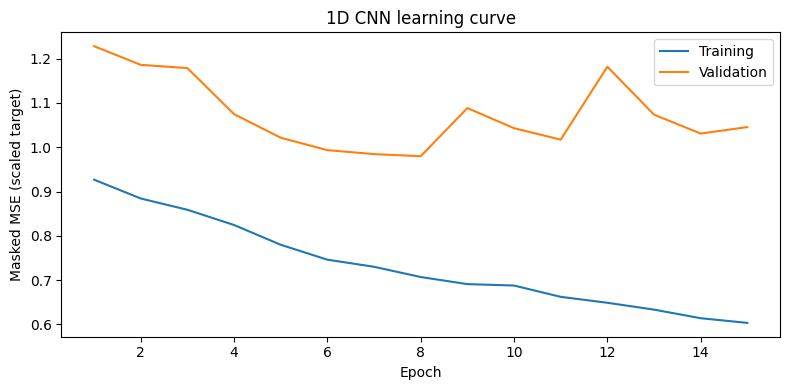

In [20]:
# Use the same training windows, loss, optimizer, epochs, and batch size as the MLP.
cnn_training_start = time.perf_counter()
for epoch in range(epochs):
    cnn_model.train()
    epoch_loss_sum, epoch_target_count = 0.0, 0
    for batch_x, batch_y, batch_mask in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        batch_mask = batch_mask.to(device)

        cnn_optimizer.zero_grad()
        predictions = cnn_model(batch_x)
        loss = criterion(predictions, batch_y, batch_mask)
        loss.backward()
        cnn_optimizer.step()
        observed_count = int(batch_mask.sum().item())
        epoch_loss_sum += loss.item() * observed_count
        epoch_target_count += observed_count

    cnn_training_losses.append(epoch_loss_sum / epoch_target_count)
    cnn_model.eval()
    with torch.no_grad():
        val_predictions = cnn_model(val_tensor)
        cnn_validation_losses.append(
            criterion(val_predictions, val_targets_tensor, val_mask_tensor).item()
        )
cnn_training_seconds = time.perf_counter() - cnn_training_start

# Validation is evaluation-only and does not update CNN parameters.
cnn_model.eval()
cnn_validation_start = time.perf_counter()
with torch.no_grad():
    cnn_pred_scaled = cnn_model(val_tensor).cpu().numpy()
cnn_prediction_seconds = time.perf_counter() - cnn_validation_start

cnn_pred_original = cnn_pred_scaled * target_scale + target_mean
cnn_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], cnn_pred_original[observed_val]))
cnn_mae = mean_absolute_error(y_val_original[observed_val], cnn_pred_original[observed_val])

print(f"Trained on {len(X_train)} training windows; evaluated on {len(X_val)} validation windows.")


plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), cnn_training_losses, label="Training")
plt.plot(range(1, epochs + 1), cnn_validation_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE (scaled target)")
plt.title("1D CNN learning curve")
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# 14. Compare the 6-hour pattern naive baseline, MLP, and 1D CNN models:

cnn_stage_comparison = pd.DataFrame([
    {
        "Model": "6-hour pattern naive",
        "Validation RMSE": baseline_rmse,
        "Validation MAE": baseline_mae,
        "Trainable parameters": 0,
        "Training time (seconds)": 0.0,
        "Validation prediction time (seconds)": baseline_prediction_seconds,
    },
    {
        "Model": "MLP",
        "Validation RMSE": mlp_rmse,
        "Validation MAE": mlp_mae,
        "Trainable parameters": mlp_parameter_count,
        "Training time (seconds)": mlp_training_seconds,
        "Validation prediction time (seconds)": mlp_prediction_seconds,
    },
    {
        "Model": "1D CNN",
        "Validation RMSE": cnn_rmse,
        "Validation MAE": cnn_mae,
        "Trainable parameters": cnn_parameter_count,
        "Training time (seconds)": cnn_training_seconds,
        "Validation prediction time (seconds)": cnn_prediction_seconds,
    },
]).sort_values("Validation RMSE").reset_index(drop=True)

cnn_stage_comparison["RMSE improvement over baseline (%)"] = (
    (baseline_rmse - cnn_stage_comparison["Validation RMSE"]) / baseline_rmse * 100
)
cnn_stage_comparison.loc[cnn_stage_comparison["Model"] == "6-hour pattern naive", "RMSE improvement over baseline (%)"] = 0.0

display(cnn_stage_comparison.round(4))
print(f"Lowest validation RMSE among these models: {cnn_stage_comparison.iloc[0]['Model']}.")


,Model,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Validation prediction time (seconds),RMSE improvement over baseline (%)
0,MLP,5.6672,3.7751,73286,7.9690,0.0030,45.4114
1,1D CNN,7.4547,5.5572,5958,11.4357,0.0297,28.1925
2,6-hour pattern naive,10.3816,7.7813,0,0.0000,0.0003,0.0000


Lowest validation RMSE among these models: MLP.


In [22]:
# 15. Grid Search on MLP hyperparameters:

# Tuning the lr, hidden-layer size, and dropout.
learning_rates = [0.001, 0.005, 0.01]
hidden_layer_options = [(128, 64), (256, 128)]
grid_epochs = epochs
grid_batch_size = batch_size
dropout_options = [0.1, 0.2]
grid_results = []
best_mlp_val_rmse = float("inf")
best_mlp_config = None
best_mlp_state = None

# Define a flexible MLP model.
class GridSearchMLP(nn.Module):
    def __init__(self, lookback, num_features, horizon, hidden_sizes, dropout):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(lookback * num_features, hidden_sizes[0]),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_sizes[0], hidden_sizes[1]),
            nn.ReLU(),
            nn.Linear(hidden_sizes[1], horizon),
        )

    def forward(self, x):
        return self.network(x)

# Grid search over the combinations of learning rates, hidden layer sizes, and dropout rates.
for trial, (lr, hidden_sizes, dropout) in enumerate(
    [(lr, widths, dropout) for lr in learning_rates
     for dropout in dropout_options for widths in hidden_layer_options],
    start=1,
):
    trial_seed = SEED + trial
    random.seed(trial_seed)
    np.random.seed(trial_seed)
    torch.manual_seed(trial_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(trial_seed)

    loader_generator = torch.Generator().manual_seed(trial_seed)
    trial_train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(np.nan_to_num(y_train, nan=0.0), dtype=torch.float32),
            torch.tensor(train_target_mask, dtype=torch.float32),
        ),
        batch_size=grid_batch_size,
        shuffle=True,
        generator=loader_generator,
    )
    trial_model = GridSearchMLP(LOOKBACK, len(features), HORIZON, hidden_sizes, dropout).to(device)
    trial_parameters = sum(p.numel() for p in trial_model.parameters() if p.requires_grad)
    trial_optimizer = torch.optim.Adam(trial_model.parameters(), lr=lr)

    trial_start = time.perf_counter()
    for epoch in range(grid_epochs):
        trial_model.train()
        for batch_x, batch_y, batch_mask in trial_train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            batch_mask = batch_mask.to(device)
            trial_optimizer.zero_grad()
            trial_loss = criterion(trial_model(batch_x), batch_y, batch_mask)
            trial_loss.backward()
            trial_optimizer.step()
    trial_training_seconds = time.perf_counter() - trial_start

    trial_model.eval()
    with torch.no_grad():
        trial_prediction_scaled = trial_model(val_tensor).cpu().numpy()
    trial_prediction_original = trial_prediction_scaled * target_scale + target_mean
    trial_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], trial_prediction_original[observed_val]))
    trial_mae = mean_absolute_error(y_val_original[observed_val], trial_prediction_original[observed_val])

    config = {
        "learning_rate": lr,
        "hidden_sizes": hidden_sizes,
        "dropout": dropout,
        "batch_size": grid_batch_size,
        "epochs": grid_epochs,
    }
    grid_results.append({
        "Trial": trial,
        "Learning rate": lr,
        "Hidden layers": str(hidden_sizes),
        "Dropout": dropout,
        "Batch size": grid_batch_size,
        "Epochs": grid_epochs,
        "Validation RMSE": trial_rmse,
        "Validation MAE": trial_mae,
        "Trainable parameters": trial_parameters,
        "Training time (seconds)": trial_training_seconds,
    })

    if trial_rmse < best_mlp_val_rmse:
        best_mlp_val_rmse = trial_rmse
        best_mlp_config = config
        best_mlp_state = deepcopy(trial_model.state_dict())

# Grid search results.
mlp_grid_results = pd.DataFrame(grid_results)
display(mlp_grid_results.round(4).set_index("Trial"))
print("Selected MLP configuration (validation RMSE):", best_mlp_config)
print(f"Best validation RMSE: {best_mlp_val_rmse:.4f}")
print("Grid search complete; selected configuration:", best_mlp_config)

,Learning rate,Hidden layers,Dropout,Batch size,Epochs,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds)
Trial,,,,,,,,,
1,0.001,"(128, 64)",0.1,64,15,5.7925,3.8450,73286,7.9488
2,0.001,"(256, 128)",0.1,64,15,5.8061,3.9437,162950,7.8190
3,0.001,"(128, 64)",0.2,64,15,5.5247,3.7325,73286,5.9450
4,0.001,"(256, 128)",0.2,64,15,5.7235,3.8218,162950,6.7084
5,0.005,"(128, 64)",0.1,64,15,6.0817,4.0780,73286,5.5218
6,0.005,"(256, 128)",0.1,64,15,6.0279,4.1367,162950,7.7978
7,0.005,"(128, 64)",0.2,64,15,5.8051,3.9391,73286,4.9139
8,0.005,"(256, 128)",0.2,64,15,5.8075,3.9820,162950,6.6825
9,0.010,"(128, 64)",0.1,64,15,6.0964,4.1797,73286,5.1897


Selected MLP configuration (validation RMSE): {'learning_rate': 0.001, 'hidden_sizes': (128, 64), 'dropout': 0.2, 'batch_size': 64, 'epochs': 15}
Best validation RMSE: 5.5247
Grid search complete; selected configuration: {'learning_rate': 0.001, 'hidden_sizes': (128, 64), 'dropout': 0.2, 'batch_size': 64, 'epochs': 15}


In [23]:
# 16. Compare all Stage 1 models:

selected_trial = mlp_grid_results.loc[mlp_grid_results["Validation RMSE"].idxmin()]
selected_config = best_mlp_config
selected_mlp = GridSearchMLP(
    LOOKBACK,
    len(features),
    HORIZON,
    selected_config["hidden_sizes"],
    selected_config["dropout"],
).to(device)
selected_mlp.load_state_dict(best_mlp_state)
selected_mlp.eval()

if device.type == "cuda":
    torch.cuda.synchronize(device)
selected_prediction_start = time.perf_counter()
with torch.no_grad():
    selected_prediction_scaled = selected_mlp(val_tensor).cpu().numpy()
if device.type == "cuda":
    torch.cuda.synchronize(device)
selected_prediction_seconds = time.perf_counter() - selected_prediction_start
selected_prediction_original = selected_prediction_scaled * target_scale + target_mean
selected_validation_rmse = np.sqrt(
    mean_squared_error(y_val_original[observed_val], selected_prediction_original[observed_val])
)
selected_validation_mae = mean_absolute_error(
    y_val_original[observed_val], selected_prediction_original[observed_val]
)
selected_parameters = sum(
    parameter.numel() for parameter in selected_mlp.parameters() if parameter.requires_grad
)

final_validation_comparison = pd.DataFrame([
    {
        "Model": "6-hour pattern naive",
        "Validation RMSE": baseline_rmse,
        "Validation MAE": baseline_mae,
        "Trainable parameters": 0,
        "Training time (seconds)": 0.0,
        "Validation prediction time (seconds)": baseline_prediction_seconds,
    },
    {
        "Model": "MLP (untuned)",
        "Validation RMSE": mlp_rmse,
        "Validation MAE": mlp_mae,
        "Trainable parameters": mlp_parameter_count,
        "Training time (seconds)": mlp_training_seconds,
        "Validation prediction time (seconds)": mlp_prediction_seconds,
    },
    {
        "Model": "1D CNN",
        "Validation RMSE": cnn_rmse,
        "Validation MAE": cnn_mae,
        "Trainable parameters": cnn_parameter_count,
        "Training time (seconds)": cnn_training_seconds,
        "Validation prediction time (seconds)": cnn_prediction_seconds,
    },
    {
        "Model": "MLP (grid-search selected)",
        "Validation RMSE": selected_validation_rmse,
        "Validation MAE": selected_validation_mae,
        "Trainable parameters": selected_parameters,
        "Training time (seconds)": selected_trial["Training time (seconds)"],
        "Validation prediction time (seconds)": selected_prediction_seconds,
    },
])
final_validation_comparison["RMSE improvement over baseline (%)"] = (
    (baseline_rmse - final_validation_comparison["Validation RMSE"]) / baseline_rmse * 100
)
final_validation_comparison = final_validation_comparison.sort_values(
    "Validation RMSE"
).reset_index(drop=True)
display(final_validation_comparison.round(4))
print("Lowest validation RMSE:", final_validation_comparison.iloc[0]["Model"])

,Model,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Validation prediction time (seconds),RMSE improvement over baseline (%)
0,MLP (grid-search selected),5.5247,3.7325,73286,5.9450,0.0070,46.7835
1,MLP (untuned),5.6672,3.7751,73286,7.9690,0.0030,45.4114
2,1D CNN,7.4547,5.5572,5958,11.4357,0.0297,28.1925
3,6-hour pattern naive,10.3816,7.7813,0,0.0000,0.0003,0.0000


Lowest validation RMSE: MLP (grid-search selected)


<h2 style="text-align: center;">STAGE 2: Sequence models (Recurrent family), CNN, TCN, Grid-Search
Hyperparameter Optimization (HPO)</h1>

In [24]:
# 17. STAGE 2 setup — HPO design is declared BEFORE any Stage 2 result is produced:


# Shared settings: identical for every new model (controlled comparison).
# Same split, windows, masked-MSE loss, optimizer (Adam) and metrics as Stage 1.
MAX_EPOCHS = 15
BATCH_SIZE = 64
PATIENCE = 4          # early stopping on validation masked MSE (once a certain value is reached and value doesnt improve, activate early stopping)
GRAD_CLIP = 1.0       # gradient-norm clipping (helps the recurrent models)
DEFAULT_CFG = {"lr": 0.001, "hidden_size": 64, "dropout": 0.1} #clipping the gradients to a certain weight (<1) to combat gradient exploding (number keeps compounding and learning diverges)

# HPO design: tune ONE model (the best new model from the untuned comparison).
HPO_SPACE = {
    "lr": [0.001, 0.005, 0.01], #Different combinations of hyperparameters will be tested

    "hidden_size": [32, 64],      # hidden units (RNN/LSTM/GRU) or channels (TCN)
                                  #hidden size = number of units in the hidden representation of model, increases model's capacity to learn
    "dropout": [0.1, 0.3],        #Randomly cuts off 10% of neurons during training to reduce risk of overfitting
}
HPO_TRIALS = list(product(*HPO_SPACE.values()))
HPO_BUDGET = 12 #number of times we will be running optimzation (testing all combinations)
assert len(HPO_TRIALS) == HPO_BUDGET

print("STAGE 2 DESIGN (fixed before results)")
print(f"  Search space : {HPO_SPACE}")
print(f"  Budget       : {HPO_BUDGET} trials (full grid), max {MAX_EPOCHS} epochs each, batch size {BATCH_SIZE}")
print("  Objective    : minimise validation RMSE (original units, observed targets only)")
print(f"  Stopping rule: early stop when validation masked MSE does not improve for {PATIENCE} epochs;")
print("                 the best-epoch weights are restored. No extra trials after the grid finishes.")
print("  Which model  : best untuned new model (RNN/LSTM/GRU/TCN) by validation RMSE")
print("  Final choice : lowest validation RMSE among all trained models; if within 0.5% of the best,")
print("                 the model with fewer parameters wins. Test data is never used.")

STAGE 2 DESIGN (fixed before results)
  Search space : {'lr': [0.001, 0.005, 0.01], 'hidden_size': [32, 64], 'dropout': [0.1, 0.3]}
  Budget       : 12 trials (full grid), max 15 epochs each, batch size 64
  Objective    : minimise validation RMSE (original units, observed targets only)
  Stopping rule: early stop when validation masked MSE does not improve for 4 epochs;
                 the best-epoch weights are restored. No extra trials after the grid finishes.
  Which model  : best untuned new model (RNN/LSTM/GRU/TCN) by validation RMSE
  Final choice : lowest validation RMSE among all trained models; if within 0.5% of the best,
                 the model with fewer parameters wins. Test data is never used.


In [25]:
# 18. Sequence model definitions:

# RNN / LSTM / GRU share one wrapper: last hidden output -> small dropout + MLP head -> HORIZON outputs.
class RecurrentForecaster(nn.Module):
    def __init__(self, cell, num_features, horizon, hidden_size=64, dropout=0.1):
        super().__init__()
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        self.rnn = rnn_cls(num_features, hidden_size, num_layers=1, batch_first=True)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, horizon),
        )

    def forward(self, x):                      # x: [batch, lookback, features]
        out, _ = self.rnn(x)
        return self.head(out[:, -1, :])        # last time step summarises the 72-hour window
#RNN: USES

# TCN: causal, dilated convolutions with residual blocks (no future leakage inside the window).
class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, dilation=dilation)

    def forward(self, x):
        return self.conv(F.pad(x, (self.pad, 0)))   # left-pad only => causal


class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_ch, out_ch, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_ch, out_ch, kernel_size, dilation)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(dropout)
        self.skip = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        out = self.drop(self.relu(self.conv1(x)))
        out = self.drop(self.relu(self.conv2(out)))
        return self.relu(out + self.skip(x))


class TCNForecaster(nn.Module):
    # Dilations (1,2,4,8,16), kernel 3, two convs per block -> receptive field = 1 + 2*2*31 = 125 >= 72 hours.
    def __init__(self, num_features, horizon, channels=64, dropout=0.1,
                 kernel_size=3, dilations=(1, 2, 4, 8, 16)):
        super().__init__()
        blocks, in_ch = [], num_features
        for d in dilations:
            blocks.append(TCNBlock(in_ch, channels, kernel_size, d, dropout))
            in_ch = channels
        self.tcn = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Linear(channels, channels), nn.ReLU(), nn.Linear(channels, horizon))

    def forward(self, x):
        h = self.tcn(x.permute(0, 2, 1))[:, :, -1]   # features at the most recent hour
        return self.head(h)

In [26]:
# 19. Shared training / evaluation helpers — used by EVERY new model and every HPO trial:

METRIC_COLS = ["Validation RMSE", "Validation MAE", "Trainable parameters",
               "Training time (seconds)", "Validation prediction time (seconds)"]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize(device)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Architecture "spec" = a small, serialisable description used to rebuild a model (also for the checkpoint).
def arch_spec(name, hidden_size, dropout):
    if name in ("RNN", "LSTM", "GRU"):
        return {"class": "RecurrentForecaster", "kwargs": {"cell": name, "hidden_size": hidden_size, "dropout": dropout}}
    if name == "TCN":
        return {"class": "TCNForecaster", "kwargs": {"hidden_size": hidden_size, "dropout": dropout}}
    raise ValueError(name)

def build_from_spec(spec):
    kw, c = spec["kwargs"], spec["class"]
    if c == "TimeSeriesMLP":
        return TimeSeriesMLP(LOOKBACK, len(features), HORIZON)
    if c == "TimeSeriesCNN":
        return TimeSeriesCNN(len(features), HORIZON)
    if c == "GridSearchMLP":
        return GridSearchMLP(LOOKBACK, len(features), HORIZON, tuple(kw["hidden_sizes"]), kw["dropout"])
    if c == "RecurrentForecaster":
        return RecurrentForecaster(kw["cell"], len(features), HORIZON, kw["hidden_size"], kw["dropout"])
    if c == "TCNForecaster":
        return TCNForecaster(len(features), HORIZON, kw["hidden_size"], kw["dropout"])
    raise ValueError(c)

def make_train_loader(seed, batch_size):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(
        TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(np.nan_to_num(y_train, nan=0.0), dtype=torch.float32),
            torch.tensor(train_target_mask, dtype=torch.float32),
        ),
        batch_size=batch_size, shuffle=True, generator=g,
    )

def evaluate_model(model):
    # Same metric protocol as Stage 1: original units, observed validation targets only.
    model.eval()
    sync(); t0 = time.perf_counter()
    with torch.no_grad():
        pred_scaled = model(val_tensor).cpu().numpy()
    sync(); pred_seconds = time.perf_counter() - t0
    pred_original = pred_scaled * target_scale + target_mean
    rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], pred_original[observed_val]))
    mae = mean_absolute_error(y_val_original[observed_val], pred_original[observed_val])
    return rmse, mae, pred_seconds, pred_original

def train_model(name, lr, hidden_size, dropout, batch_size=BATCH_SIZE,
                max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED):
    set_seed(seed)                                  # same seed for every model/trial => controlled comparison
    model = build_from_spec(arch_spec(name, hidden_size, dropout)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_train_loader(seed, batch_size)

    train_curve, val_curve = [], []
    best_val, best_state, best_epoch, wait = float("inf"), None, 0, 0

    sync(); t0 = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        model.train()
        loss_sum, n_obs = 0.0, 0
        for bx, by, bm in loader:
            bx, by, bm = bx.to(device), by.to(device), bm.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by, bm)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            k = int(bm.sum().item())
            loss_sum += loss.item() * k
            n_obs += k
        train_curve.append(loss_sum / n_obs)

        model.eval()
        with torch.no_grad():
            v = criterion(model(val_tensor), val_targets_tensor, val_mask_tensor).item()
        val_curve.append(v)

        if v < best_val - 1e-6:
            best_val, best_epoch, wait = v, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    sync(); train_seconds = time.perf_counter() - t0   # includes per-epoch validation passes

    model.load_state_dict(best_state)                 # restore best epoch
    rmse, mae, pred_seconds, _ = evaluate_model(model)
    result = {
        "Model": name, "lr": lr, "hidden_size": hidden_size, "dropout": dropout,
        "Validation RMSE": rmse, "Validation MAE": mae,
        "Trainable parameters": count_params(model),
        "Training time (seconds)": train_seconds,
        "Validation prediction time (seconds)": pred_seconds,
        "Best epoch": best_epoch, "Epochs run": len(train_curve),
        "train_curve": train_curve, "val_curve": val_curve,
    }
    return result, model

In [27]:
# 20. Train RNN, LSTM, GRU and TCN with identical default settings (untuned):

untuned_results, untuned_models = [], {}
for name in ["RNN", "LSTM", "GRU", "TCN"]:
    res, mdl = train_model(name, **DEFAULT_CFG)
    untuned_results.append(res)
    untuned_models[name] = mdl
    print(f"{name:5s} | val RMSE {res['Validation RMSE']:.4f} | params {res['Trainable parameters']:,} "
          f"| best epoch {res['Best epoch']}/{res['Epochs run']} | {res['Training time (seconds)']:.1f}s")

RNN   | val RMSE 5.5095 | params 9,222 | best epoch 5/9 | 17.2s
LSTM  | val RMSE 5.5968 | params 23,238 | best epoch 6/10 | 22.9s
GRU   | val RMSE 5.3998 | params 18,566 | best epoch 9/13 | 77.1s
TCN   | val RMSE 5.1547 | params 117,638 | best epoch 6/10 | 129.8s


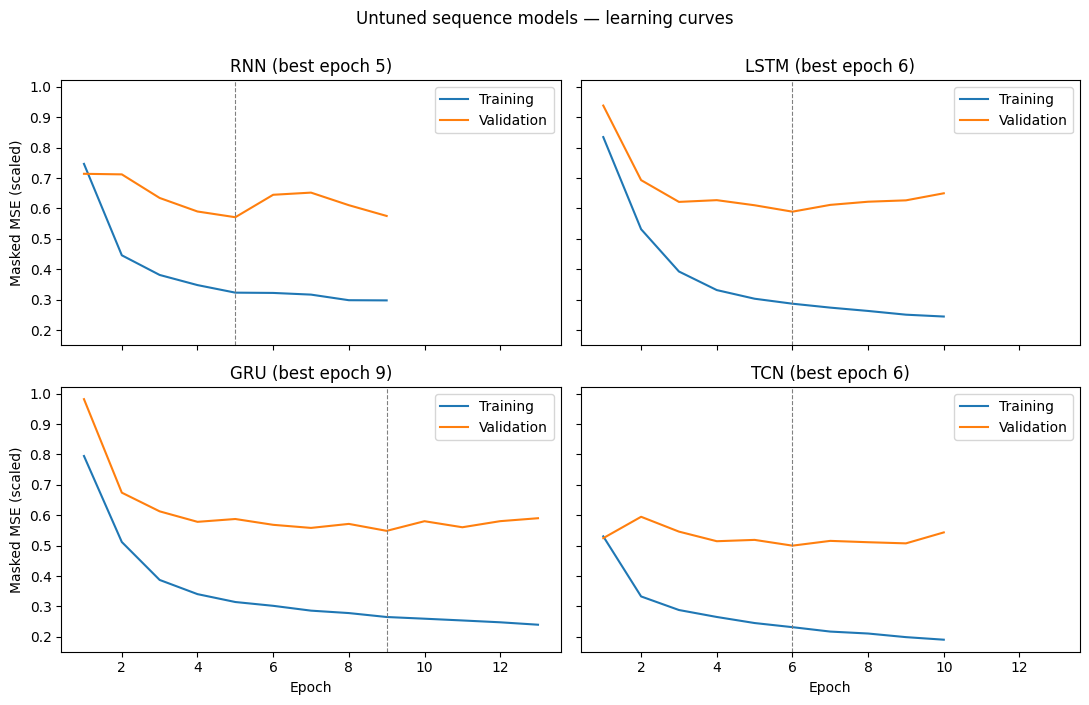

In [28]:
# 21. Learning curves for the untuned sequence models:

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, res in zip(axes.ravel(), untuned_results):
    ep = range(1, len(res["train_curve"]) + 1)
    ax.plot(ep, res["train_curve"], label="Training")
    ax.plot(ep, res["val_curve"], label="Validation")
    ax.axvline(res["Best epoch"], color="gray", ls="--", lw=0.8)
    ax.set_title(f"{res['Model']} (best epoch {res['Best epoch']})")
    ax.legend()
for ax in axes[-1]:
    ax.set_xlabel("Epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("Masked MSE (scaled)")
fig.suptitle("Untuned sequence models — learning curves", y=1.0)
fig.tight_layout()
plt.show()

In [29]:
# 22. Controlled comparison so far (Stage 1 models + new untuned models) and the HPO target:

base = final_validation_comparison[["Model"] + METRIC_COLS].copy()
new_rows = pd.DataFrame([
    {"Model": f"{r['Model']} (untuned)", **{c: r[c] for c in METRIC_COLS}} for r in untuned_results
])
stage2_untuned = pd.concat([base, new_rows], ignore_index=True)
stage2_untuned["RMSE improvement over baseline (%)"] = (
    (baseline_rmse - stage2_untuned["Validation RMSE"]) / baseline_rmse * 100
)
stage2_untuned = stage2_untuned.sort_values("Validation RMSE").reset_index(drop=True)
display(stage2_untuned.round(4))

# Pre-declared rule: tune the new model with the lowest untuned validation RMSE.
tune_name = min(untuned_results, key=lambda r: r["Validation RMSE"])["Model"]
print(f"Model selected for HPO (best untuned new model by validation RMSE): {tune_name}")

,Model,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Validation prediction time (seconds),RMSE improvement over baseline (%)
0,TCN (untuned),5.1547,3.5523,117638,129.7639,0.4522,50.3475
1,GRU (untuned),5.3998,3.7145,18566,77.1492,0.0736,47.9863
2,RNN (untuned),5.5095,3.7959,9222,17.1506,0.0256,46.9300
3,MLP (grid-search selected),5.5247,3.7325,73286,5.9450,0.0070,46.7835
4,LSTM (untuned),5.5968,3.9163,23238,22.9097,0.1598,46.0892
5,MLP (untuned),5.6672,3.7751,73286,7.9690,0.0030,45.4114
6,1D CNN,7.4547,5.5572,5958,11.4357,0.0297,28.1925
7,6-hour pattern naive,10.3816,7.7813,0,0.0000,0.0003,0.0000


Model selected for HPO (best untuned new model by validation RMSE): TCN


In [30]:
# 23. HPO: full pre-declared grid on the selected model (12 trials, same seed/split/windows/metrics):

hpo_rows, hpo_models = [], {}
for trial, (lr, hidden_size, dropout) in enumerate(HPO_TRIALS, start=1):
    res, mdl = train_model(tune_name, lr, hidden_size, dropout)
    hpo_rows.append({
        "Trial": trial, "Learning rate": lr, "Hidden size": hidden_size, "Dropout": dropout,
        "Validation RMSE": res["Validation RMSE"], "Validation MAE": res["Validation MAE"],
        "Trainable parameters": res["Trainable parameters"],
        "Training time (seconds)": res["Training time (seconds)"],
        "Best epoch": res["Best epoch"], "Epochs run": res["Epochs run"],
    })
    hpo_models[trial] = mdl
    print(f"Trial {trial:2d}/{HPO_BUDGET} | lr={lr} hidden={hidden_size} dropout={dropout} "
          f"| val RMSE {res['Validation RMSE']:.4f} | stopped at epoch {res['Epochs run']}")

Trial  1/12 | lr=0.001 hidden=32 dropout=0.1 | val RMSE 5.1987 | stopped at epoch 13
Trial  2/12 | lr=0.001 hidden=32 dropout=0.3 | val RMSE 5.1072 | stopped at epoch 15
Trial  3/12 | lr=0.001 hidden=64 dropout=0.1 | val RMSE 5.1547 | stopped at epoch 10
Trial  4/12 | lr=0.001 hidden=64 dropout=0.3 | val RMSE 5.1774 | stopped at epoch 13
Trial  5/12 | lr=0.005 hidden=32 dropout=0.1 | val RMSE 5.2315 | stopped at epoch 10
Trial  6/12 | lr=0.005 hidden=32 dropout=0.3 | val RMSE 5.2484 | stopped at epoch 12
Trial  7/12 | lr=0.005 hidden=64 dropout=0.1 | val RMSE 5.3055 | stopped at epoch 6
Trial  8/12 | lr=0.005 hidden=64 dropout=0.3 | val RMSE 5.0667 | stopped at epoch 15
Trial  9/12 | lr=0.01 hidden=32 dropout=0.1 | val RMSE 5.3198 | stopped at epoch 15
Trial 10/12 | lr=0.01 hidden=32 dropout=0.3 | val RMSE 5.3801 | stopped at epoch 10
Trial 11/12 | lr=0.01 hidden=64 dropout=0.1 | val RMSE 5.3054 | stopped at epoch 15
Trial 12/12 | lr=0.01 hidden=64 dropout=0.3 | val RMSE 5.4309 | stopp

,Learning rate,Hidden size,Dropout,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Best epoch,Epochs run
Trial,,,,,,,,,
1,0.001,32,0.1,5.1987,3.6642,30150,96.5122,9,13
2,0.001,32,0.3,5.1072,3.5127,30150,95.3520,12,15
3,0.001,64,0.1,5.1547,3.5523,117638,131.9563,6,10
4,0.001,64,0.3,5.1774,3.6200,117638,151.0798,9,13
5,0.005,32,0.1,5.2315,3.6830,30150,53.1998,6,10
6,0.005,32,0.3,5.2484,3.6947,30150,64.3170,8,12
7,0.005,64,0.1,5.3055,3.6714,117638,75.3499,2,6
8,0.005,64,0.3,5.0667,3.4101,117638,4587.6319,12,15
9,0.010,32,0.1,5.3198,3.6861,30150,240.9527,11,15


Best trial: 8 -> lr=0.005, hidden=64, dropout=0.3, val RMSE 5.0667


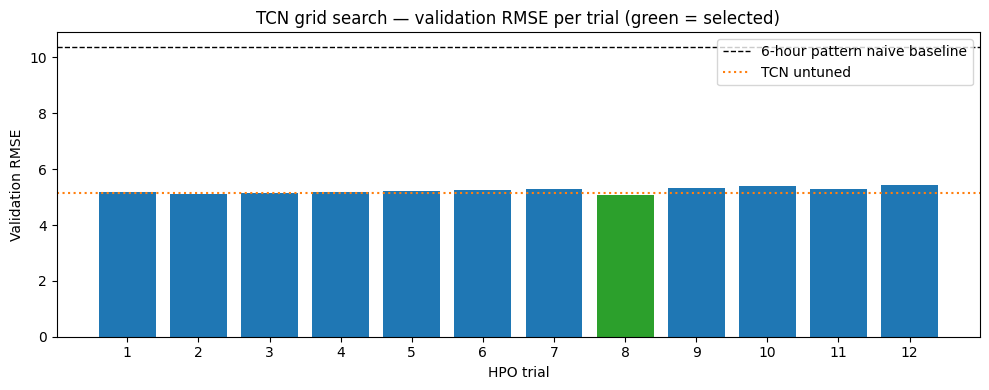

In [31]:
# 24. HPO evidence — trials table and plot:

hpo_df = pd.DataFrame(hpo_rows)
display(hpo_df.round(4).set_index("Trial"))

# Selection: lowest validation RMSE; ties (within 0.5%) go to fewer parameters (rule declared in Cell 17).
best_rmse = hpo_df["Validation RMSE"].min()
near_best = hpo_df[hpo_df["Validation RMSE"] <= best_rmse * 1.005]
best_trial = int(near_best.sort_values(["Trainable parameters", "Validation RMSE"]).iloc[0]["Trial"])
best_row = hpo_df[hpo_df["Trial"] == best_trial].iloc[0]
tuned_model = hpo_models[best_trial]
print(f"Best trial: {best_trial} -> lr={best_row['Learning rate']}, hidden={int(best_row['Hidden size'])}, "
      f"dropout={best_row['Dropout']}, val RMSE {best_row['Validation RMSE']:.4f}")

untuned_ref = next(r for r in untuned_results if r["Model"] == tune_name)["Validation RMSE"]
colors = ["tab:green" if t == best_trial else "tab:blue" for t in hpo_df["Trial"]]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hpo_df["Trial"], hpo_df["Validation RMSE"], color=colors)
ax.axhline(baseline_rmse, color="k", ls="--", lw=1, label="6-hour pattern naive baseline")
ax.axhline(untuned_ref, color="tab:orange", ls=":", lw=1.5, label=f"{tune_name} untuned")
ax.set_xticks(hpo_df["Trial"])
ax.set_xlabel("HPO trial")
ax.set_ylabel("Validation RMSE")
ax.set_title(f"{tune_name} grid search — validation RMSE per trial (green = selected)")
ax.legend()
fig.tight_layout()
plt.show()

In [32]:
# 25. Full controlled comparison and final model selection (validation evidence only):

# Registry of every trained model: name -> (architecture spec, model object).
registry = {
    "MLP (untuned)": ({"class": "TimeSeriesMLP", "kwargs": {}}, mlp_model),
    "1D CNN": ({"class": "TimeSeriesCNN", "kwargs": {}}, cnn_model),
    "MLP (grid-search selected)": (
        {"class": "GridSearchMLP",
         "kwargs": {"hidden_sizes": list(best_mlp_config["hidden_sizes"]), "dropout": best_mlp_config["dropout"]}},
        selected_mlp),
}
for name, mdl in untuned_models.items():
    registry[f"{name} (untuned)"] = (arch_spec(name, DEFAULT_CFG["hidden_size"], DEFAULT_CFG["dropout"]), mdl)
tuned_label = f"{tune_name} (HPO-tuned)"
registry[tuned_label] = (arch_spec(tune_name, int(best_row["Hidden size"]), float(best_row["Dropout"])), tuned_model)

# Add the tuned model's row to the comparison table.
tuned_row = pd.DataFrame([{
    "Model": tuned_label,
    "Validation RMSE": best_row["Validation RMSE"], "Validation MAE": best_row["Validation MAE"],
    "Trainable parameters": int(best_row["Trainable parameters"]),
    "Training time (seconds)": best_row["Training time (seconds)"],
    "Validation prediction time (seconds)": evaluate_model(tuned_model)[2],
}])
stage2_final = pd.concat([stage2_untuned[["Model"] + METRIC_COLS], tuned_row], ignore_index=True)
stage2_final["RMSE improvement over baseline (%)"] = (
    (baseline_rmse - stage2_final["Validation RMSE"]) / baseline_rmse * 100
)
stage2_final = stage2_final.sort_values("Validation RMSE").reset_index(drop=True)
display(stage2_final.round(4))

# Selection rule (declared in Cell 17): lowest validation RMSE among trained models;
# within 0.5% of the best -> fewer parameters wins. The baseline is a reference, not a candidate.
candidates = stage2_final[stage2_final["Model"] != "6-hour pattern naive"]
best_r = candidates["Validation RMSE"].min()
close = candidates[candidates["Validation RMSE"] <= best_r * 1.005]
final_row = close.sort_values(["Trainable parameters", "Validation RMSE"]).iloc[0]
final_name = final_row["Model"]
final_spec, final_model = registry[final_name]

print(f"FINAL MODEL: {final_name}")
print(f"  Validation RMSE {final_row['Validation RMSE']:.4f} | MAE {final_row['Validation MAE']:.4f} "
      f"| params {int(final_row['Trainable parameters']):,} "
      f"| improvement over baseline {final_row['RMSE improvement over baseline (%)']:.2f}%")
print(f"  Architecture spec: {final_spec}")

,Model,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Validation prediction time (seconds),RMSE improvement over baseline (%)
0,TCN (HPO-tuned),5.0667,3.4101,117638,4587.6319,1.0335,51.1948
1,TCN (untuned),5.1547,3.5523,117638,129.7639,0.4522,50.3475
2,GRU (untuned),5.3998,3.7145,18566,77.1492,0.0736,47.9863
3,RNN (untuned),5.5095,3.7959,9222,17.1506,0.0256,46.9300
4,MLP (grid-search selected),5.5247,3.7325,73286,5.9450,0.0070,46.7835
5,LSTM (untuned),5.5968,3.9163,23238,22.9097,0.1598,46.0892
6,MLP (untuned),5.6672,3.7751,73286,7.9690,0.0030,45.4114
7,1D CNN,7.4547,5.5572,5958,11.4357,0.0297,28.1925
8,6-hour pattern naive,10.3816,7.7813,0,0.0000,0.0003,0.0000


FINAL MODEL: TCN (HPO-tuned)
  Validation RMSE 5.0667 | MAE 3.4101 | params 117,638 | improvement over baseline 51.19%
  Architecture spec: {'class': 'TCNForecaster', 'kwargs': {'hidden_size': 64, 'dropout': 0.3}}


In [33]:
# 26. Checkpoint the selected model + configuration + preprocessing state in ONE file for the final stage:

CHECKPOINT_PATH = "stage2_checkpoint.pt"

final_rmse, final_mae, _, final_val_pred = evaluate_model(final_model)

checkpoint = {
    # Model
    "model_name": final_name,
    "arch_spec": final_spec,
    "state_dict": {k: v.detach().cpu() for k, v in final_model.state_dict().items()},
    # Configuration
    "hpo_space": HPO_SPACE,
    "tuned_model_family": tune_name,
    "best_hpo_trial": {"trial": best_trial, "lr": float(best_row["Learning rate"]),
                       "hidden_size": int(best_row["Hidden size"]), "dropout": float(best_row["Dropout"])},
    "training": {"max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE, "patience": PATIENCE,
                 "grad_clip": GRAD_CLIP, "optimizer": "Adam", "loss": "masked_mse", "seed": SEED},
    "validation_metrics": {"rmse": float(final_rmse), "mae": float(final_mae),
                           "baseline_rmse": float(baseline_rmse)},
    # Preprocessing state (needed to transform test data exactly like train data)
    "features": list(features),
    "target_col": TARGET_COL,
    "target_idx": int(target_idx),
    "lookback": int(LOOKBACK),
    "horizon": int(HORIZON),
    "missing_value_code": -200,
    "imputation": "forward-fill, then training-set median fallback",
    "training_feature_medians": {k: float(v) for k, v in training_feature_medians.items()},
    "scaler_mean": [float(x) for x in scaler.mean_],
    "scaler_scale": [float(x) for x in scaler.scale_],
    "target_mean": float(target_mean),
    "target_scale": float(target_scale),
}
torch.save(checkpoint, CHECKPOINT_PATH)
print(f"Saved checkpoint to {CHECKPOINT_PATH}")

# ---- Verify the checkpoint round-trips (rebuild model, reload weights, reproduce predictions) ----
loaded = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
reloaded_model = build_from_spec(loaded["arch_spec"]).to(device)
reloaded_model.load_state_dict(loaded["state_dict"])
reloaded_model.eval()

_, _, _, reloaded_pred = evaluate_model(reloaded_model)
print("Reloaded predictions match saved model:", np.allclose(reloaded_pred, final_val_pred, atol=1e-5))

# Preprocessing state is sufficient to reproduce the scaled validation inputs.
mean = np.array(loaded["scaler_mean"]); scale = np.array(loaded["scaler_scale"])
rescaled_val = (val_processed[loaded["features"]].to_numpy() - mean) / scale
print("Saved scaler state reproduces scaled validation inputs:", np.allclose(rescaled_val, val_scaled))

Saved checkpoint to stage2_checkpoint.pt
Reloaded predictions match saved model: True
Saved scaler state reproduces scaled validation inputs: True


### Predicted vs. actual (final model, validation set)

Plots below compare the final model's forecasts with the observed benzene values (original units). Windows overlap (stride = 1 h), so each hour is predicted by several windows; the time-series panels show the 1-step-ahead and the last-step-ahead forecast of every window. Hours with a missing target are left blank in the plots and excluded from the metrics.

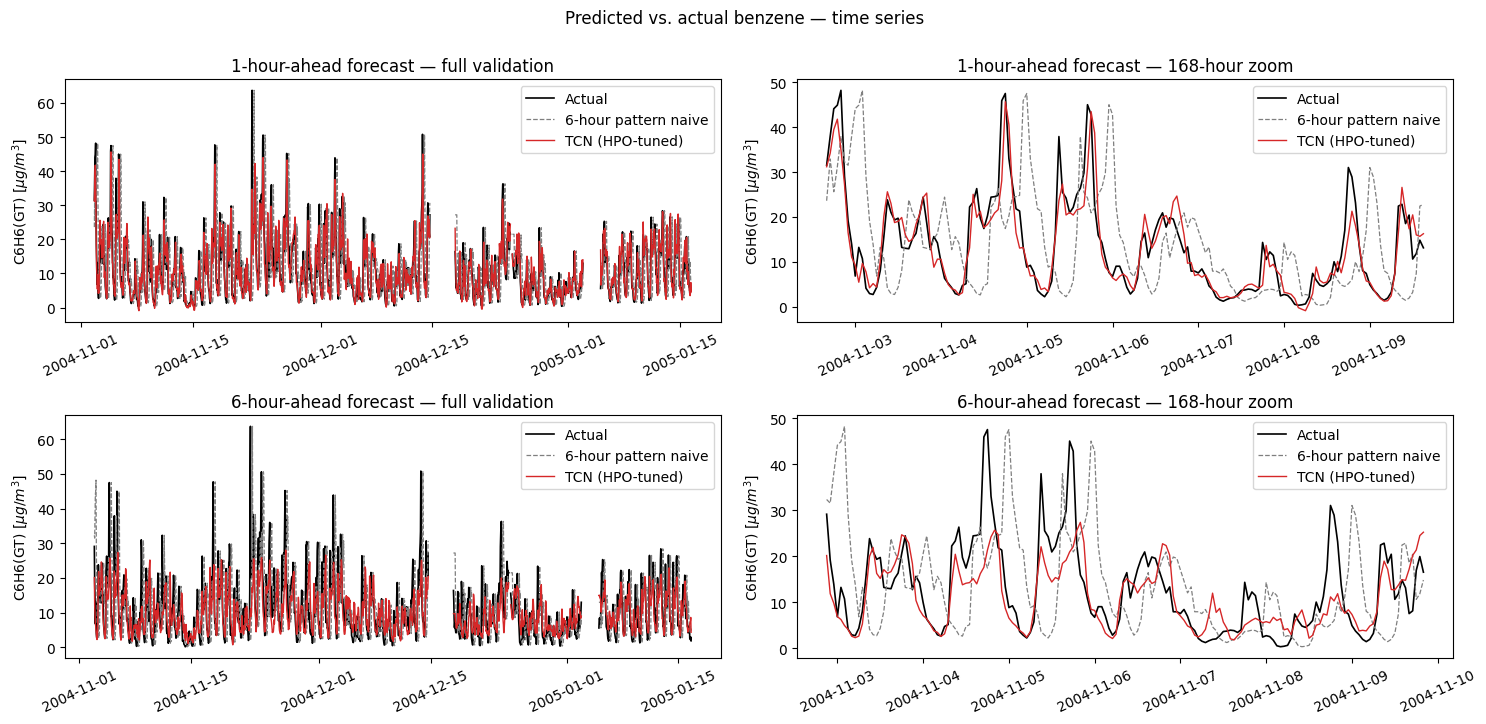

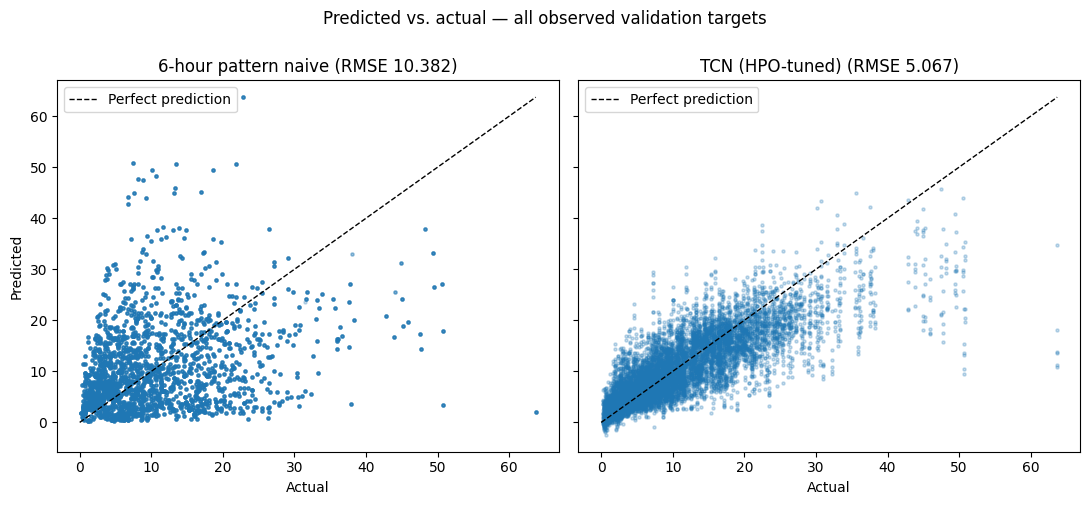

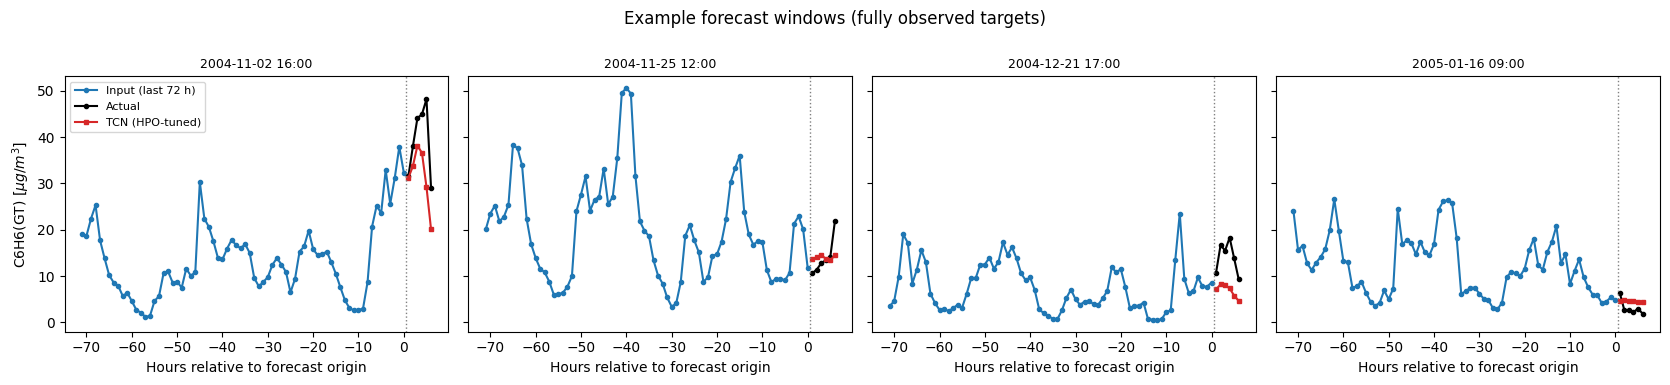

In [34]:
# 27. Predicted vs. actual plots — final model vs. 6-hour pattern naive baseline (validation set, original units):

def plot_predicted_vs_actual(pred_original, label, zoom_hours=168, n_examples=4):
    n_windows = len(pred_original)
    pos = np.arange(n_windows)[:, None] + LOOKBACK + np.arange(HORIZON)[None, :]   # val_df row each prediction targets
    times = val_df.index.to_numpy()[pos]                                             # [n_windows, HORIZON]

    actual = np.where(observed_val, y_val_original, np.nan)
    pred = np.where(observed_val, pred_original, np.nan)
    base = np.where(observed_val, baseline_pred_original, np.nan)
    steps = sorted({0, HORIZON - 1})

    # Zoom on the zoom_hours-long stretch with the most observed targets (1-step-ahead).
    cover = np.convolve(observed_val[:, 0].astype(float), np.ones(zoom_hours), mode="valid")
    z0 = int(cover.argmax()); z1 = z0 + zoom_hours

    # --- Figure A: time series, full validation (left) and zoom (right), one row per forecast step ---
    fig, axes = plt.subplots(len(steps), 2, figsize=(15, 3.6 * len(steps)), squeeze=False)
    for r, k in enumerate(steps):
        for c, (sl, title) in enumerate([(slice(None), "full validation"), (slice(z0, z1), f"{zoom_hours}-hour zoom")]):
            ax = axes[r, c]
            ax.plot(times[sl, k], actual[sl, k], color="k", lw=1.2, label="Actual")
            ax.plot(times[sl, k], base[sl, k], color="tab:gray", lw=0.9, ls="--", label="6-hour pattern naive")
            ax.plot(times[sl, k], pred[sl, k], color="tab:red", lw=1.0, label=label)
            ax.set_title(f"{k + 1}-hour-ahead forecast — {title}")
            ax.set_ylabel(rf"{TARGET_COL} [$\mu g/m^3$]")
            ax.tick_params(axis="x", rotation=25)
            ax.legend(loc="upper right")
    fig.suptitle("Predicted vs. actual benzene — time series", y=1.0)
    fig.tight_layout(); plt.show()

    # --- Figure B: scatter of predicted vs. actual over all observed targets ---
    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
    lim = [0, float(np.nanmax(actual))]
    for ax, p, name in [(axes[0], base, "6-hour pattern naive"), (axes[1], pred, label)]:
        ax.scatter(actual[observed_val], p[observed_val], s=5, alpha=0.25)
        ax.plot(lim, lim, "k--", lw=1, label="Perfect prediction")
        rmse = np.sqrt(np.mean((p[observed_val] - actual[observed_val]) ** 2))
        ax.set_title(f"{name} (RMSE {rmse:.3f})")
        ax.set_xlabel("Actual"); ax.legend(loc="upper left")
    axes[0].set_ylabel("Predicted")
    fig.suptitle("Predicted vs. actual — all observed validation targets", y=1.0)
    fig.tight_layout(); plt.show()

    # --- Figure C: example windows (input context + HORIZON-hour forecast vs. actual) ---
    full_obs = np.where(observed_val.all(axis=1))[0]        # windows whose whole target is observed
    if len(full_obs) > 0:
        chosen = full_obs[np.linspace(0, len(full_obs) - 1, min(n_examples, len(full_obs))).astype(int)]
        fig, axes = plt.subplots(1, len(chosen), figsize=(4.2 * len(chosen), 3.8), sharey=True, squeeze=False)
        for ax, i in zip(axes[0], chosen):
            context = X_val[i, :, target_idx] * target_scale + target_mean   # imputed input benzene
            ax.plot(range(-LOOKBACK + 1, 1), context, color="tab:blue", marker="o", ms=3, label="Input (last %d h)" % LOOKBACK)
            ax.plot(range(1, HORIZON + 1), y_val_original[i], color="k", marker="o", ms=3, label="Actual")
            ax.plot(range(1, HORIZON + 1), pred_original[i], color="tab:red", marker="s", ms=3, label=label)
            ax.axvline(0.5, color="gray", ls=":", lw=1)
            ax.set_title(str(val_df.index[i + LOOKBACK])[:16], fontsize=9)
            ax.set_xlabel("Hours relative to forecast origin")
        axes[0, 0].set_ylabel(rf"{TARGET_COL} [$\mu g/m^3$]"); axes[0, 0].legend(fontsize=8)
        fig.suptitle("Example forecast windows (fully observed targets)", y=1.0)
        fig.tight_layout(); plt.show()

_, _, _, final_val_pred_plot = evaluate_model(final_model)
plot_predicted_vs_actual(final_val_pred_plot, final_name)


## STAGE 3: Final full-project demonstration
### S3-00. Presentation map and evaluation contract

| Demo sequence / requirement | Notebook evidence |
|---|---|
| 1. Problem, source, target, units, audit, representative plots | Introduction; S1-DATA; Stage 1 audit; Fig. 1-2; S3-01 |
| 2. Chronology, alignment, leakage controls, baselines, metrics | Stage 1 preprocessing/windows; Table S3-1; S3-01/02 |
| 3. MLP, CNN, recurrent, TCN, Transformer under one protocol | Stage 1-2 definitions; S3-03/04; Table S3-2 |
| 4. Validation-only HPO, cost, winner and rationale | S3-02 budget; Table S3-3; Fig. S3-1/2; S3-06 |
| 5. Reload locked finalist; test all models once | S3-09/10; Table S3-6 |
| 6. Time/frequency and failure regimes | Fig. S3-3; Tables S3-8/9; Fig. S3-5 |
| 7. Error bands, sensitivity, deployment limits, next steps | S3-07/08; Tables S3-4/5/7; S3-13 |
| 8. Hardware deployment | Optional; not claimed or measured here |
| 9. Commit, environment, run order, saved model, smoke test | S3-14/15; README; environment record; Table S3-10 |


In [ ]:
# S3-01. Table S3-1. Split, timestamp and window alignment audit.
import hashlib
import json
import platform
import subprocess
import importlib.metadata
from datetime import datetime, timezone

split_audit = []
for label, frame, x, y, mask in [
    ('Train', train_df, X_train, y_train, train_target_mask),
    ('Validation', val_df, X_val, y_val, val_target_mask),
    ('Test (labels sealed)', test_df, X_test, None, None),
]:
    assert len(x) == (len(frame) - LOOKBACK - HORIZON) // STRIDE + 1
    assert x.shape[1:] == (LOOKBACK, len(features)) and np.isfinite(x).all()
    assert frame.index.is_unique
    assert (frame.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all()
    origins = np.arange(len(x)) * STRIDE + LOOKBACK - 1
    assert (frame.index[origins + 1] - frame.index[origins] == pd.Timedelta(hours=1)).all()
    if y is not None:
        assert y.shape == mask.shape == (len(x), HORIZON) and mask.sum() > 0
    split_audit.append({'Split': label, 'First row': frame.index[0], 'Last row': frame.index[-1],
        'Rows': len(frame), 'Windows': len(x), 'Input shape': str(x.shape),
        'Observed labels': int(mask.sum()) if mask is not None else 'sealed',
        'First input ends': frame.index[LOOKBACK-1], 'First target starts': frame.index[LOOKBACK],
        'Last target ends': frame.index[origins[-1] + HORIZON]})
assert train_df.index[-1] < val_df.index[0] < test_df.index[0]
assert np.allclose(scaler.mean_, train_processed[features].mean().to_numpy())
assert np.allclose(training_feature_medians, train_feature_raw.median())
assert np.array_equal(val_target_mask, np.isfinite(y_val))
print('Table S3-1. Chronological split and exact hourly window alignment')
split_table = pd.DataFrame(split_audit)
display(split_table)
print('Historical target and sensor/weather values only; no future observed covariates.')

def s3_metrics(actual, prediction, mask):
    assert actual.shape == prediction.shape == mask.shape
    assert np.isfinite(prediction).all()
    valid = mask & np.isfinite(actual)
    n = int(valid.sum())
    if not n:
        return {'RMSE': np.nan, 'MAE': np.nan, 'Bias': np.nan, 'Observed pairs': 0}
    error = prediction[valid] - actual[valid]
    return {'RMSE': float(np.sqrt(np.mean(error**2))), 'MAE': float(np.mean(np.abs(error))),
            'Bias': float(np.mean(error)), 'Observed pairs': n}

def s3_naive(x, kind):
    if kind == 'Persistence':
        pred = np.repeat(x[:, -1:, target_idx], HORIZON, axis=1)
    elif kind == 'Daily seasonal naive (24h)':
        assert LOOKBACK >= 24 and HORIZON <= 24
        pred = x[:, -24:-24+HORIZON, target_idx]
    elif kind == '6-hour pattern naive':
        pred = x[:, -HORIZON:, target_idx]
    else:
        raise ValueError(kind)
    return pred * target_scale + target_mean

### S3-02. Predeclared design, HPO budget and analysis rules

Before producing Stage 3 results, fix these decisions:

* Refit every architecture registered in Stage 2 plus a Transformer using seed 42,
  Adam, learning rate 0.001, batch size 64, masked MSE, a 15-epoch maximum,
  patience 4, gradient clipping 1.0 and best-validation-epoch restoration.
  Previously selected architectures remain validation-informed; this is not a fresh independent experiment.
* Tune the strongest controlled neural candidate by validation RMSE. The grid has exactly
  8 trials: learning rate {0.0003, 0.001}, weight decay {0, 0.0001}, batch size {32, 64}.
  Architecture stays fixed. No trial is added after seeing results. Each trial uses the same
  seed, epoch cap, patience and loss. Epoch stopping uses scaled validation MSE, equivalent
  to the original-unit RMSE ranking for the same labels.
* Final selection includes **all three baselines**, controlled neural refits and the tuned winner.
  Within 0.5% of the best validation RMSE, choose fewer parameters, then lower RMSE,
  then name. Baselines may win. Runtime is reported as an operational trade-off.
* Maximum new training budget: (number of registered architectures + 1 + 8) × 15 epochs.
  Earlier Stage 1/2 searches are additional historical costs; their actual logged seconds are reported.
* Calibrate per-horizon 90% empirical absolute-error bands on validation residuals only.
  The same validation set participates in selection, so these are descriptive bands with
  no independent conformal or guaranteed 90% coverage claim.
* Robustness: fixed 0.1-standard-deviation input noise and a six-hour sensor outage,
  assessed on validation only without retuning. Failure regimes are fixed before test:
  high benzene above the training 90th percentile; rapid change above the training
  90th percentile of absolute hourly changes; daytime 06:00-17:59 versus night.
* The final test cache is read on repeated display. A different experiment fingerprint
  causes an error instead of silently retesting. Never revise choices using test results.

In [ ]:
# S3-03. Transformer: projected inputs + sinusoidal position + encoder + direct 6-output head.
class TransformerForecaster(nn.Module):
    def __init__(self, num_features, horizon, lookback=72, d_model=64,
                 nhead=4, num_layers=2, dropout=0.1):
        super().__init__()
        assert d_model % nhead == 0 and d_model % 2 == 0
        self.projection = nn.Linear(num_features, d_model)
        pos = torch.arange(lookback, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32)
                        * (-np.log(10000.0) / d_model))
        pe = torch.zeros(lookback, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos*div), torch.cos(pos*div)
        self.register_buffer('position', pe.unsqueeze(0))
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead,
            dim_feedforward=4*d_model, dropout=dropout, activation='gelu', batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, horizon))
    def forward(self, x):
        h = self.projection(x) + self.position[:, :x.shape[1]]
        return self.head(self.encoder(h)[:, -1])

# Bidirectional attention is confined to the historical input window. No forecast labels
# enter the encoder, so a causal decoder mask is unnecessary for this direct forecaster.
# Independent layer initialization avoids identical copied encoder-layer initial weights.
def s3_build(spec):
    if spec['class'] == 'TransformerForecaster':
        model = TransformerForecaster(len(features), HORIZON, LOOKBACK, **spec['kwargs'])
        for block in model.encoder.layers:
            for parameter in block.parameters():
                if parameter.dim() > 1:
                    nn.init.xavier_uniform_(parameter)
        return model
    return build_from_spec(spec)

def s3_predict(model, x, batch=64):
    model.eval()
    parts = []
    sync(); started = time.perf_counter()
    with torch.no_grad():
        for start in range(0, len(x), batch):
            bx = torch.as_tensor(x[start:start+batch], dtype=torch.float32, device=device)
            parts.append(model(bx).cpu().numpy())
    sync()
    return np.concatenate(parts) * target_scale + target_mean, time.perf_counter()-started

def s3_fit(spec, lr=0.001, weight_decay=0.0, batch=64, seed=42):
    set_seed(seed)
    model = s3_build(spec).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = make_train_loader(seed, batch)
    best, best_epoch, bad, state = float('inf'), 0, 0, None
    curve = []
    sync(); started = time.perf_counter()
    for epoch in range(1, 16):
        model.train()
        total, count = 0.0, 0
        for bx, by, bm in loader:
            if bm.sum().item() == 0:
                continue
            bx, by, bm = bx.to(device), by.to(device), bm.to(device)
            opt.zero_grad()
            loss = masked_mse_loss(model(bx), by, bm)
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite training loss; stop before opening test.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            k = int(bm.sum().item()); total += loss.item()*k; count += k
        pred, _ = s3_predict(model, X_val)
        metric = s3_metrics(y_val_original, pred, val_target_mask)
        val_mse = (metric['RMSE']/target_scale)**2
        curve.append({'Epoch': epoch, 'Training masked MSE': total/max(count, 1),
                      'Validation masked MSE': val_mse})
        if val_mse < best - 1e-6:
            best, best_epoch, bad = val_mse, epoch, 0
            state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= 4:
                break
    sync(); seconds = time.perf_counter()-started
    if state is None:
        raise RuntimeError('No valid checkpoint; test remains sealed.')
    model.load_state_dict(state)
    # Warm-up is validation-only; synchronized timing excludes training and warm-up.
    s3_predict(model, X_val[:min(64, len(X_val))])
    pred, inference = s3_predict(model, X_val)
    metric = s3_metrics(y_val_original, pred, val_target_mask)
    return {'spec': copy.deepcopy(spec), 'state_dict': state, 'curve': curve,
            'Validation RMSE': metric['RMSE'], 'Validation MAE': metric['MAE'],
            'Trainable parameters': count_params(model), 'Training seconds': seconds,
            'Validation inference seconds': inference, 'Best epoch': best_epoch,
            'Epochs run': len(curve), 'Seed': seed,
            'config': {'lr': lr, 'weight_decay': weight_decay, 'batch': batch, 'seed': seed},
            'val_prediction': pred}

S3_ARTIFACTS = Path('artifacts/stage3')
S3_ARTIFACTS.mkdir(parents=True, exist_ok=True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
# warn_only acknowledges operations/device versions that may still be nondeterministic.
S3_SPECS = {name: copy.deepcopy(pair[0]) for name, pair in registry.items()}
S3_SPECS['Transformer'] = {'class': 'TransformerForecaster', 'kwargs': {
    'd_model': 64, 'nhead': 4, 'num_layers': 2, 'dropout': 0.1}}
S3_GRID = list(product([0.0003, 0.001], [0.0, 0.0001], [32, 64]))
assert len(S3_GRID) == 8
print('Budget:', len(S3_SPECS), 'controlled refits + 8 trials; maximum',
      (len(S3_SPECS)+8)*15, 'new epochs; early stopping may reduce this.')

In [ ]:
# S3-04. Table S3-2. All architectures refitted under the SAME training protocol.
s3_records = {}
for name, spec in S3_SPECS.items():
    s3_records[name] = s3_fit(spec)
    print(name, '| validation RMSE:', round(s3_records[name]['Validation RMSE'], 4))
S3_BASELINES = ['Persistence', 'Daily seasonal naive (24h)', '6-hour pattern naive']
for name in S3_BASELINES:
    started = time.perf_counter(); pred = s3_naive(X_val, name)
    elapsed = time.perf_counter()-started
    metric = s3_metrics(y_val_original, pred, val_target_mask)
    s3_records[name] = {'spec': None, 'state_dict': None, 'curve': [],
        'Validation RMSE': metric['RMSE'], 'Validation MAE': metric['MAE'],
        'Trainable parameters': 0, 'Training seconds': 0.0,
        'Validation inference seconds': elapsed, 'Best epoch': 0, 'Epochs run': 0,
        'Seed': 42, 'config': {'rule': name}, 'val_prediction': pred}

def s3_table(records):
    cols = ['Validation RMSE', 'Validation MAE', 'Trainable parameters', 'Training seconds',
            'Validation inference seconds', 'Best epoch', 'Epochs run', 'Seed']
    return pd.DataFrame([{'Model': n, **{k: r[k] for k in cols}} for n, r in records.items()])

controlled_table = s3_table(s3_records).sort_values(['Validation RMSE', 'Model'])
print('Table S3-2. Controlled validation comparison (original units)')
display(controlled_table.round(5))
tune_s3 = controlled_table[controlled_table['Model'].isin(S3_SPECS)].iloc[0]['Model']
print('HPO target selected by validation evidence:', tune_s3)
controlled_table.to_csv(S3_ARTIFACTS/'controlled_validation.csv', index=False)

In [ ]:
# S3-05. Table S3-3 and Fig. S3-1. Exactly eight validation-only HPO trials.
s3_hpo, s3_trial_records = [], {}
for trial, (lr, decay, batch) in enumerate(S3_GRID, 1):
    rec = s3_fit(S3_SPECS[tune_s3], lr=lr, weight_decay=decay, batch=batch)
    s3_trial_records[trial] = rec
    s3_hpo.append({'Trial': trial, 'Family': tune_s3, 'Learning rate': lr,
        'Weight decay': decay, 'Batch': batch,
        **{k: rec[k] for k in ['Validation RMSE', 'Validation MAE', 'Trainable parameters',
                               'Training seconds', 'Best epoch', 'Epochs run', 'Seed']}})
    print('Completed trial', trial, 'of 8; validation RMSE', rec['Validation RMSE'])
s3_hpo_table = pd.DataFrame(s3_hpo)
close = s3_hpo_table[s3_hpo_table['Validation RMSE'] <= s3_hpo_table['Validation RMSE'].min()*1.005]
chosen_trial = int(close.sort_values(['Trainable parameters', 'Validation RMSE', 'Trial']).iloc[0]['Trial'])
s3_tuned_label = tune_s3 + ' [Stage 3 HPO]'
s3_records[s3_tuned_label] = s3_trial_records[chosen_trial]
print('Table S3-3. Bounded validation-only HPO trials; selected trial:', chosen_trial)
display(s3_hpo_table.round(5))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(s3_hpo_table['Trial'], s3_hpo_table['Validation RMSE'],
       color=['tab:green' if t == chosen_trial else 'tab:blue' for t in s3_hpo_table['Trial']])
ax.axhline(s3_records[tune_s3]['Validation RMSE'], color='k', ls='--', label='Controlled untuned reference')
ax.set(xlabel='Trial', ylabel='Validation RMSE (micrograms/m³)',
       title='Fig. S3-1. Validation-only HPO; green = selected trial')
ax.legend(); fig.tight_layout(); plt.show()
s3_hpo_table.to_csv(S3_ARTIFACTS/'hpo_trials.csv', index=False)
print('New controlled refit seconds:', sum(s3_records[n]['Training seconds'] for n in S3_SPECS))
print('New HPO seconds (all trials):', s3_hpo_table['Training seconds'].sum())
print('Historical Stage 1 grid seconds:', mlp_grid_results['Training time (seconds)'].sum())
print('Historical Stage 2 grid seconds:', hpo_df['Training time (seconds)'].sum())

In [ ]:
# S3-06. Evidence-based FINAL selection before test access; Fig. S3-2 learning curves.
selection_table = s3_table(s3_records)
near = selection_table[selection_table['Validation RMSE'] <= selection_table['Validation RMSE'].min()*1.005]
winner_row = near.sort_values(['Trainable parameters', 'Validation RMSE', 'Model']).iloc[0]
s3_winner = str(winner_row['Model'])
winner_rec = s3_records[s3_winner]
reference_rmse = s3_records['Persistence']['Validation RMSE']
selection_table['RMSE improvement vs persistence (%)'] = (
    100*(reference_rmse-selection_table['Validation RMSE'])/reference_rmse if reference_rmse else np.nan)
print('Table S3-2b. Final validation selection, including baselines')
display(selection_table.sort_values('Validation RMSE').round(5))
display(Markdown(f"**Locked candidate:** {s3_winner}. Validation RMSE "
    f"{winner_rec['Validation RMSE']:.4f}, MAE {winner_rec['Validation MAE']:.4f}; "
    f"{winner_rec['Trainable parameters']:,} parameters. It won the predeclared "
    "0.5% tolerance / parameter-count / RMSE rule. No test score participates."))
print('Selected architecture:', winner_rec['spec'])
print('Selected configuration:', winner_rec['config'])
print('Comparison cost includes validation passes; inference includes tensor transfer and batching.')
print('Parameter counts measure size, not peak memory or on-device latency.')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ['Transformer', s3_tuned_label]:
    curve = pd.DataFrame(s3_records[name]['curve'])
    axes[0].plot(curve['Epoch'], curve['Training masked MSE'], label=name+' train')
    axes[1].plot(curve['Epoch'], curve['Validation masked MSE'], label=name+' validation')
for ax in axes:
    ax.set(xlabel='Epoch', ylabel='Scaled masked MSE'); ax.legend(fontsize=8)
fig.suptitle('Fig. S3-2. Transformer and HPO-selected learning curves')
fig.tight_layout(); plt.show()
selection_table.to_csv(S3_ARTIFACTS/'final_validation_selection.csv', index=False)

In [ ]:
# S3-07. Table S3-4. Validation-calibrated 90% empirical error bands; fixed regimes.
ALPHA = 0.10
val_residual = np.where(val_target_mask, np.abs(winner_rec['val_prediction']-y_val_original), np.nan)
band_radius = []
for k in range(HORIZON):
    errors = val_residual[:, k][np.isfinite(val_residual[:, k])]
    if len(errors) < 20:
        raise ValueError('Too few validation observations for reliable empirical bands.')
    # Conservative finite-sample order statistic; descriptive, not a coverage guarantee.
    rank = min(len(errors), int(np.ceil((len(errors)+1)*(1-ALPHA))))
    band_radius.append(float(np.sort(errors)[rank-1]))
band_radius = np.array(band_radius)
band_table = pd.DataFrame({'Horizon (hours)': np.arange(1, HORIZON+1),
    'Validation observed': val_target_mask.sum(axis=0), '90% band half-width': band_radius})
print('Table S3-4. Validation-only empirical band calibration (micrograms/m³)')
display(band_table.round(4))
train_observed = train_target_observed.dropna().to_numpy()
HIGH_THRESHOLD = float(np.quantile(train_observed, 0.90))
train_change = train_target_observed.diff().abs().dropna().to_numpy()
RAPID_THRESHOLD = float(np.quantile(train_change, 0.90))
print('Fixed failure thresholds from training: high benzene >', HIGH_THRESHOLD,
      '; absolute hourly change >', RAPID_THRESHOLD)
band_table.to_csv(S3_ARTIFACTS/'band_calibration.csv', index=False)

In [ ]:
# S3-08. Table S3-5. Fixed validation robustness checks, no retraining or reselection.
robustness_rows = []
rng = np.random.default_rng(42)
noisy = X_val + rng.normal(0, 0.1, X_val.shape)
outage = X_val.copy()
# Simulate six hours without any of the three PT08 sensors: hold last available response.
sensor_idx = [i for i, name in enumerate(features) if name.startswith('PT08.')]
for j in sensor_idx:
    outage[:, -6:, j] = outage[:, -7:-6, j]
if winner_rec['spec'] is not None:
    robustness_model = s3_build(winner_rec['spec']).to(device)
    robustness_model.load_state_dict(winner_rec['state_dict'])
for label, inputs in [('Clean', X_val), ('Noise: 0.1 training SD', noisy),
                      ('PT08 sensors: 6h outage', outage)]:
    if winner_rec['spec'] is None:
        prediction = s3_naive(inputs, s3_winner)
    else:
        prediction, _ = s3_predict(robustness_model, inputs)
    metric = s3_metrics(y_val_original, prediction, val_target_mask)
    robustness_rows.append({'Scenario': label, **metric,
        'RMSE change vs clean (%)': 100*(metric['RMSE']/winner_rec['Validation RMSE']-1)
            if winner_rec['Validation RMSE'] else np.nan})
robustness_table = pd.DataFrame(robustness_rows)
print('Table S3-5. Locked-candidate sensitivity on validation')
display(robustness_table.round(4))
print('Synthetic perturbations are diagnostics, not proof of real deployment reliability.')
robustness_table.to_csv(S3_ARTIFACTS/'validation_robustness.csv', index=False)

In [ ]:
# S3-09. Fig. S3-3. Training-only time/frequency insight; do not use test to choose periods.
series = train_processed[TARGET_COL].to_numpy(dtype=float)
centered = series-series.mean()
n = len(centered)
tapered = centered*np.hanning(n)
frequency = np.fft.rfftfreq(n, d=1.0)
power = np.abs(np.fft.rfft(tapered))**2
nonzero = frequency > 0
period = 1/frequency[nonzero]
power_nonzero = power[nonzero]
within = (period >= 2) & (period <= 24*14)
peak = float(period[within][np.argmax(power_nonzero[within])])
lags = np.arange(1, 169)
acf = np.array([np.corrcoef(centered[:-lag], centered[lag:])[0, 1] for lag in lags])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lags, acf)
axes[0].set(xlabel='Lag (hours)', ylabel='Lag correlation', title='Training autocorrelation')
order = np.argsort(period[within])
axes[1].plot(period[within][order], power_nonzero[within][order])
axes[1].set(xlabel='Period (hours)', ylabel='Relative FFT power', xscale='log', title='Training periodogram')
for ax in axes:
    for hour in [24, 168]: ax.axvline(hour, color='gray', ls='--', lw=0.8)
fig.suptitle('Fig. S3-3. Temporal structure of training benzene')
fig.tight_layout(); plt.show()
print(f'Strongest plotted training spectral period: {peak:.2f} h; '
      f'lag-24 correlation {acf[23]:.3f}; lag-168 correlation {acf[167]:.3f}.')
print('Daily persistence is assessed by the explicit 24h baseline; a 72h lookback contains')
print('three days but cannot directly represent a full weekly cycle. Forward filling can')
print('inflate autocorrelation and spectral peaks; FFT power is descriptive, not significance evidence.')

In [ ]:
# S3-10a. Lock model, preprocessing, configurations and protocol BEFORE test labels are made.
def s3_json_hash(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()

def s3_array_hash(*arrays):
    digest = hashlib.sha256()
    for value in arrays:
        a = np.ascontiguousarray(value)
        digest.update(str((a.shape, a.dtype)).encode()); digest.update(a.tobytes())
    return digest.hexdigest()

def s3_state_hash(state):
    digest = hashlib.sha256()
    for key, value in sorted((state or {}).items()):
        digest.update(key.encode()); digest.update(s3_array_hash(value.cpu().numpy()).encode())
    return digest.hexdigest()

def s3_git(*args):
    try:
        return subprocess.check_output(['git', *args], text=True, stderr=subprocess.DEVNULL).strip()
    except (OSError, subprocess.CalledProcessError):
        return 'unavailable'

preprocessing_state = {'features': list(features), 'target': TARGET_COL, 'target_idx': target_idx,
    'lookback': LOOKBACK, 'horizon': HORIZON, 'stride': STRIDE,
    'scaler_mean': scaler.mean_.tolist(), 'scaler_scale': scaler.scale_.tolist(),
    'training_medians': training_feature_medians.to_dict(),
    'imputation': 'within-split forward fill, then training median',
    'split_sizes': [len(train_df), len(val_df), len(test_df)],
    'test_first': str(test_df.index[0]), 'test_last': str(test_df.index[-1])}
protocol = {'version': 'stage3-v1', 'winner': s3_winner, 'preprocessing': preprocessing_state,
    'data_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'development_hash': s3_array_hash(X_train, y_train, X_val, y_val),
    'test_input_hash': s3_array_hash(X_test),
    'candidates': {n: {'spec': r['spec'], 'config': r['config'],
                       'state_hash': s3_state_hash(r['state_dict'])} for n, r in s3_records.items()},
    'selection_rule': 'validation RMSE; within 0.5% fewer parameters, RMSE, name',
    'band_radius': band_radius.tolist(), 'alpha': ALPHA,
    'high_threshold': HIGH_THRESHOLD, 'rapid_threshold': RAPID_THRESHOLD,
    'seed': 42, 'max_epochs': 15, 'patience': 4, 'grad_clip': 1.0,
    'hpo_grid': S3_GRID, 'hpo_family': tune_s3, 'chosen_trial': chosen_trial,
    'git_commit_at_run': s3_git('rev-parse', 'HEAD')}
experiment_id = s3_json_hash(protocol)
lock_path = S3_ARTIFACTS/'locked_finalist.pt'
cache_path = S3_ARTIFACTS/'final_test_predictions.npz'
manifest_path = S3_ARTIFACTS/'lock_manifest.json'
if manifest_path.exists():
    previous = json.loads(manifest_path.read_text(encoding='utf-8'))
    if previous['experiment_id'] != experiment_id:
        raise RuntimeError('An existing experiment is locked. Do not retest after changing choices. '
                           'Preserve the previous artifacts and investigate the mismatch.')
elif cache_path.exists() or lock_path.exists():
    raise RuntimeError('Partial lock artifacts found. Inspect provenance before continuing.')
else:
    payload = {'experiment_id': experiment_id, 'model_name': s3_winner,
        'spec': winner_rec['spec'], 'state_dict': winner_rec['state_dict'],
        'config': winner_rec['config'], 'preprocessing': preprocessing_state,
        'validation_metrics': {'RMSE': winner_rec['Validation RMSE'], 'MAE': winner_rec['Validation MAE']},
        'band_radius': band_radius.tolist(),
        'smoke_input': torch.tensor(X_val[:2], dtype=torch.float32),
        'smoke_prediction': torch.tensor(winner_rec['val_prediction'][:2], dtype=torch.float32)}
    torch.save(payload, lock_path)
    # Preserve every comparator checkpoint so the test table is reproducible.
    torch.save({n: {k: v for k, v in r.items() if k != 'val_prediction'}
                for n, r in s3_records.items()}, S3_ARTIFACTS/'comparison_checkpoints.pt')
    manifest_path.write_text(json.dumps({'experiment_id': experiment_id,
        'locked_utc': datetime.now(timezone.utc).isoformat(), 'protocol': protocol},
        indent=2, default=str), encoding='utf-8')
print('Locked experiment:', experiment_id)
print('Saved finalist:', lock_path, '| no test metrics have been used for selection.')

### S3-10b. Final test boundary
The next cell is the only cell that creates test labels and runs the frozen candidate set
against them. It loads the saved finalist rather than evaluating an in-memory substitute.
Each candidate's test forecasts are produced in one batched pass and saved; later plots,
tables, regime diagnostics and reruns use that cache. It does not tune, refit or select
a winner from the test ranking. Rolling test inputs include measurements that have become
historical by each forecast origin; this is rolling-origin evaluation, not a single fixed-origin
six-hour forecast of the entire test period. A cache cannot make a previously inspected
test set untouched: disclose any prior manual test use separately.

In [ ]:
# S3-10b. Table S3-6. One final controlled test comparison, then immutable cached predictions.
locked = torch.load(lock_path, map_location='cpu', weights_only=True)
assert locked['experiment_id'] == experiment_id
assert locked['preprocessing'] == preprocessing_state
if cache_path.exists():
    with np.load(cache_path, allow_pickle=False) as cache:
        if str(cache['experiment_id'].item()) != experiment_id:
            raise RuntimeError('Cache fingerprint mismatch; do not evaluate another experiment on this test.')
        test_actual = cache['actual'].copy(); test_mask = cache['mask'].copy()
        test_times = cache['times'].copy()
        test_names = cache['names'].tolist()
        test_predictions = cache['predictions'].copy()
        test_seconds = cache['inference_seconds'].copy()
    print('Loaded the existing test cache; no test inference repeated.')
else:
    raw_test_target = test_missing[TARGET_COL].to_numpy(dtype=float)
    test_positions = (np.arange(len(X_test))*STRIDE)[:, None] + LOOKBACK + np.arange(HORIZON)[None, :]
    test_actual = raw_test_target[test_positions]
    test_mask = np.isfinite(test_actual)
    test_times = test_df.index.to_numpy()[test_positions]
    assert test_mask.sum() > 0
    # Checkpoint scaler/median round-trip before trusting test transformation.
    prep = locked['preprocessing']
    test_inputs_check = test_feature_raw[prep['features']].ffill().fillna(pd.Series(prep['training_medians']))
    test_scaled_check = (test_inputs_check.to_numpy()-np.array(prep['scaler_mean']))/np.array(prep['scaler_scale'])
    assert np.allclose(test_scaled_check, test_scaled)
    test_names, predictions, seconds = list(s3_records), [], []
    for name in test_names:
        rec = s3_records[name]
        if rec['spec'] is None:
            started = time.perf_counter(); pred = s3_naive(X_test, name)
            elapsed = time.perf_counter()-started
        else:
            spec = locked['spec'] if name == s3_winner else rec['spec']
            state = locked['state_dict'] if name == s3_winner else rec['state_dict']
            model = s3_build(spec).to(device); model.load_state_dict(state)
            # Warm-up uses validation inputs, not an extra test pass.
            s3_predict(model, X_val[:min(64, len(X_val))])
            pred, elapsed = s3_predict(model, X_test)
        assert pred.shape == test_actual.shape and np.isfinite(pred).all()
        predictions.append(pred); seconds.append(elapsed)
    test_predictions = np.stack(predictions); test_seconds = np.asarray(seconds)
    # Atomic replace avoids treating an incomplete write as a valid cache.
    temporary_cache = S3_ARTIFACTS/'final_test_predictions.tmp.npz'
    np.savez_compressed(temporary_cache, experiment_id=np.array(experiment_id),
        actual=test_actual, mask=test_mask, times=test_times, names=np.asarray(test_names),
        predictions=test_predictions, inference_seconds=test_seconds)
    temporary_cache.replace(cache_path)
test_pred_by_name = dict(zip(test_names, test_predictions))
persistence_test_rmse = s3_metrics(test_actual, test_pred_by_name['Persistence'], test_mask)['RMSE']
final_rows = []
for name, pred, seconds in zip(test_names, test_predictions, test_seconds):
    metric = s3_metrics(test_actual, pred, test_mask)
    rec = s3_records[name]
    final_rows.append({'Model': name, 'Locked finalist': name == s3_winner,
        'Validation RMSE': rec['Validation RMSE'], 'Test RMSE': metric['RMSE'],
        'Test MAE': metric['MAE'], 'Test bias': metric['Bias'], 'Observed pairs': metric['Observed pairs'],
        'RMSE improvement vs persistence (%)': 100*(persistence_test_rmse-metric['RMSE'])/persistence_test_rmse
            if persistence_test_rmse else np.nan,
        'Trainable parameters': rec['Trainable parameters'], 'Training seconds': rec['Training seconds'],
        'Test inference seconds': seconds, 'Milliseconds/window (batched)': 1000*seconds/len(X_test),
        'Seed': rec['Seed']})
final_test_table = pd.DataFrame(final_rows)  # preserve pre-test candidate order, not test-based selection
assert final_test_table['Observed pairs'].nunique() == 1
print('Table S3-6. Final test comparison; selection stays fixed at:', s3_winner)
display(final_test_table.round(5))
final_test_table.to_csv(S3_ARTIFACTS/'final_test_comparison.csv', index=False)
finalist_test_prediction = test_pred_by_name[s3_winner]

In [ ]:
# S3-11. Table S3-7 / Fig. S3-4. Per-horizon performance, band coverage, fixed first-week plot.
lower = finalist_test_prediction-band_radius[None, :]
upper = finalist_test_prediction+band_radius[None, :]
interval_rows = []
for k in range(HORIZON):
    valid = test_mask[:, k]
    metric = s3_metrics(test_actual[:, k:k+1], finalist_test_prediction[:, k:k+1], test_mask[:, k:k+1])
    coverage = np.mean((test_actual[valid, k] >= lower[valid, k]) &
                       (test_actual[valid, k] <= upper[valid, k])) if valid.any() else np.nan
    interval_rows.append({'Horizon (hours)': k+1, **metric,
        'Empirical coverage (%)': 100*coverage, 'Mean width': 2*band_radius[k]})
horizon_table = pd.DataFrame(interval_rows)
print('Table S3-7. Finalist horizon errors and validation-calibrated empirical bands')
display(horizon_table.round(4))
stop = min(168, len(X_test))  # first 168 origins, fixed before inspecting errors
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, k in zip(axes, [0, HORIZON-1]):
    actual = np.where(test_mask[:stop, k], test_actual[:stop, k], np.nan)
    ax.plot(test_times[:stop, k], actual, color='k', label='Observed')
    ax.plot(test_times[:stop, k], finalist_test_prediction[:stop, k], color='tab:red', label=s3_winner)
    ax.plot(test_times[:stop, k], test_pred_by_name['Persistence'][:stop, k],
            color='gray', ls='--', label='Persistence')
    ax.fill_between(test_times[:stop, k], lower[:stop, k], upper[:stop, k],
                    color='tab:red', alpha=0.15, label='90% validation empirical band')
    ax.set_title(f'{k+1}-hour-ahead; first {stop} test origins')
    ax.set_ylabel('Benzene (micrograms/m³)'); ax.legend(fontsize=8)
fig.suptitle('Fig. S3-4. Final test forecasts with empirical error bands')
fig.tight_layout(); plt.show()
horizon_table.to_csv(S3_ARTIFACTS/'horizon_errors_and_bands.csv', index=False)
print('Bands cover individual horizon errors, not the simultaneous six-hour trajectory.')
print('No distribution-free guarantee: validation reuse, overlapping windows and drift can reduce coverage.')

In [ ]:
# S3-12. Tables S3-8/9; Fig. S3-5. Predeclared regimes + explicitly diagnostic worst example.
positions = (np.arange(len(X_test))*STRIDE)[:, None]+LOOKBACK+np.arange(HORIZON)[None, :]
raw_target = test_missing[TARGET_COL].to_numpy(dtype=float)
previous_actual = raw_target[positions-1]
change = np.abs(test_actual-previous_actual)
hours = pd.DatetimeIndex(test_times.reshape(-1)).hour.to_numpy().reshape(test_times.shape)
rapid_known = test_mask & np.isfinite(previous_actual)
regimes = {
    'All observed': test_mask,
    'High benzene (train q90)': test_mask & (test_actual > HIGH_THRESHOLD),
    'Lower benzene': test_mask & (test_actual <= HIGH_THRESHOLD),
    'Rapid change (train q90)': rapid_known & (change > RAPID_THRESHOLD),
    'Slower change': rapid_known & (change <= RAPID_THRESHOLD),
    'Daytime (06-17)': test_mask & (hours >= 6) & (hours < 18),
    'Night (18-05)': test_mask & ((hours < 6) | (hours >= 18)),
}
failure_rows = []
for regime, mask in regimes.items():
    metric = s3_metrics(test_actual, finalist_test_prediction, mask)
    base_metric = s3_metrics(test_actual, test_pred_by_name['Persistence'], mask)
    failure_rows.append({'Regime': regime, **metric, 'Persistence RMSE': base_metric['RMSE']})
failure_table = pd.DataFrame(failure_rows)
print('Table S3-8. Failure regimes fixed using training thresholds, no test-driven retuning')
display(failure_table.round(4))
failure_table.to_csv(S3_ARTIFACTS/'failure_regimes.csv', index=False)
eligible = failure_table[(failure_table['Regime'] != 'All observed') &
                         (failure_table['Observed pairs'] >= 20)]
if not eligible.empty:
    worst = eligible.loc[eligible['RMSE'].idxmax()]
    print(f"Largest measured regime RMSE: {worst['Regime']} = {worst['RMSE']:.4f}, "
          f"based on {int(worst['Observed pairs'])} observed pairs. Regimes overlap; counts are dependent.")
print('High/rapid labels are retrospective diagnostics; they are not available future routing inputs.')

# Honest worst-case illustration: selected AFTER testing for explanation only, never model choice.
window_mse = np.where(test_mask, (finalist_test_prediction-test_actual)**2, 0).sum(axis=1)
counts = test_mask.sum(axis=1)
window_mse = np.divide(window_mse, counts, out=np.full(len(counts), np.nan), where=counts > 0)
worst_i = int(np.nanargmax(window_mse))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(-LOOKBACK+1, 1), X_test[worst_i, :, target_idx]*target_scale+target_mean,
        color='tab:blue', label='Historical input (imputed where missing)')
ax.plot(np.arange(1, HORIZON+1), np.where(test_mask[worst_i], test_actual[worst_i], np.nan),
        'ko-', label='Observed future')
ax.plot(np.arange(1, HORIZON+1), finalist_test_prediction[worst_i], 'ro-', label='Finalist')
ax.plot(np.arange(1, HORIZON+1), test_pred_by_name['Persistence'][worst_i], '--', label='Persistence')
ax.axvline(0.5, color='gray', ls=':')
ax.set(xlabel='Hours relative to origin', ylabel='Benzene (micrograms/m³)',
       title=f'Fig. S3-5. Diagnostic worst observed test window; first target {test_times[worst_i, 0]}')
ax.legend(); fig.tight_layout(); plt.show()

# Moving-block bootstrap over ORIGINS preserves within-window horizon dependence and
# short-range overlap; it is descriptive under nonstationarity. Fixed budget: 400 × 168h blocks.
block = min(max(1, int(np.ceil(168/STRIDE))), len(X_test))
rng = np.random.default_rng(42)
bootstrap = []
for _ in range(400):
    starts = rng.integers(0, len(X_test)-block+1, size=int(np.ceil(len(X_test)/block)))
    sample = np.concatenate([np.arange(s, s+block) for s in starts])[:len(X_test)]
    a = s3_metrics(test_actual[sample], finalist_test_prediction[sample], test_mask[sample])['RMSE']
    b = s3_metrics(test_actual[sample], test_pred_by_name['Persistence'][sample], test_mask[sample])['RMSE']
    bootstrap.append((a, a-b))
bootstrap = np.asarray(bootstrap)
bootstrap_table = pd.DataFrame([
    {'Quantity': 'Finalist RMSE', '2.5%': np.nanquantile(bootstrap[:, 0], .025),
     '97.5%': np.nanquantile(bootstrap[:, 0], .975)},
    {'Quantity': 'Finalist minus persistence RMSE', '2.5%': np.nanquantile(bootstrap[:, 1], .025),
     '97.5%': np.nanquantile(bootstrap[:, 1], .975)}])
print('Table S3-9. Descriptive 95% moving-block bootstrap ranges; 400 resamples, block', block, 'origins')
display(bootstrap_table.round(4))
bootstrap_table.to_csv(S3_ARTIFACTS/'block_bootstrap.csv', index=False)
print('One held-out period and nonstationarity limit interval interpretation; this is not an IID significance test.')

In [ ]:
# S3-13. Result-linked conclusions generated from actual evidence, no invented performance claims.
locked_test_row = final_test_table.loc[final_test_table['Model'] == s3_winner].iloc[0]
validation_rmse = winner_rec['Validation RMSE']
observed_coverage = np.mean(((test_actual >= lower) & (test_actual <= upper))[test_mask])*100
display(Markdown(
    f"**Final conclusion.** Validation selected **{s3_winner}** using the documented rule. "
    f"Its held-out RMSE is **{locked_test_row['Test RMSE']:.4f}** and MAE "
    f"**{locked_test_row['Test MAE']:.4f} micrograms/m³** over "
    f"{int(locked_test_row['Observed pairs']):,} observed origin/horizon pairs. "
    f"RMSE improvement versus persistence is **{locked_test_row['RMSE improvement vs persistence (%)']:.2f}%** "
    "(negative means worse). The test ranking does not change the locked model. "
    f"Test/validation RMSE ratio is {locked_test_row['Test RMSE']/validation_rmse:.3f}; "
    f"empirical band coverage is {observed_coverage:.2f}% against a descriptive 90% target. "
    "Use Tables S3-7/8 to explain horizon and regime dependence; use Table S3-9 to assess "
    "the stability of the observed persistence comparison."))
worst_perturbation = robustness_table.loc[robustness_table['RMSE'].idxmax()]
print('Largest measured validation perturbation RMSE:', worst_perturbation['Scenario'],
      worst_perturbation['RMSE'])
print('Transformer validation RMSE:', s3_records['Transformer']['Validation RMSE'],
      '| locked finalist validation RMSE:', validation_rmse,
      '| Transformer parameters:', s3_records['Transformer']['Trainable parameters'])

### Reliability, limitations, operational meaning and next steps

* Success means lower error on the same observed origin/horizon pairs as the baselines,
  supported by Table S3-6, with stable horizons/regimes in Tables S3-7/8. A lower global
  RMSE alone does not establish accuracy during pollution peaks. A negative improvement
  must be reported as a failure to beat persistence.
* Peak and abrupt-change errors can reflect slow responses, scarce extreme examples,
  or covariate shift. These are possible mechanisms, not causal findings. Fig. S3-5
  deliberately exposes the largest observed window error; it is not representative performance.
* One Italian deployment and one chronological holdout limit geographic and seasonal
  generalization. Sensor drift and cross-sensitivity are documented by the dataset provider.
  Missing labels may be informative: metrics apply to observed labels, not unobserved pollution.
  Forward filling during long outages may conceal stale inputs. Synthetic outage/noise
  diagnostics do not cover all measurement faults.

In [ ]:
# S3-15. Standalone checkpoint smoke test; no training or test evaluation.
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display

class TimeSeriesMLP(nn.Module):
    def __init__(self, lookback, num_features, horizon):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(lookback * num_features, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, horizon),
        )

    def forward(self, x):
        return self.network(x)

class TimeSeriesCNN(nn.Module):
    def __init__(self, num_features, horizon):
        super().__init__()
        self.conv1 = nn.Conv1d(
            in_channels=num_features,
            out_channels=64,
            kernel_size=3,
            padding=1,
        )
        self.relu = nn.ReLU()
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.head = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, horizon),
        )

    def forward(self, x):
        # Input is [batch, lookback, features]; Conv1d expects channels second.
        x = x.permute(0, 2, 1)
        x = self.relu(self.conv1(x))
        x = self.pool(x).squeeze(-1)
        return self.head(x)

class GridSearchMLP(nn.Module):
    def __init__(self, lookback, num_features, horizon, hidden_sizes, dropout):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(lookback * num_features, hidden_sizes[0]),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_sizes[0], hidden_sizes[1]),
            nn.ReLU(),
            nn.Linear(hidden_sizes[1], horizon),
        )

    def forward(self, x):
        return self.network(x)

class RecurrentForecaster(nn.Module):
    def __init__(self, cell, num_features, horizon, hidden_size=64, dropout=0.1):
        super().__init__()
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        self.rnn = rnn_cls(num_features, hidden_size, num_layers=1, batch_first=True)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, horizon),
        )

    def forward(self, x):                      # x: [batch, lookback, features]
        out, _ = self.rnn(x)
        return self.head(out[:, -1, :])

class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, dilation=dilation)

    def forward(self, x):
        return self.conv(F.pad(x, (self.pad, 0)))

class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_ch, out_ch, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_ch, out_ch, kernel_size, dilation)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(dropout)
        self.skip = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        out = self.drop(self.relu(self.conv1(x)))
        out = self.drop(self.relu(self.conv2(out)))
        return self.relu(out + self.skip(x))

class TCNForecaster(nn.Module):
    # Dilations (1,2,4,8,16), kernel 3, two convs per block -> receptive field = 1 + 2*2*31 = 125 >= 72 hours.
    def __init__(self, num_features, horizon, channels=64, dropout=0.1,
                 kernel_size=3, dilations=(1, 2, 4, 8, 16)):
        super().__init__()
        blocks, in_ch = [], num_features
        for d in dilations:
            blocks.append(TCNBlock(in_ch, channels, kernel_size, d, dropout))
            in_ch = channels
        self.tcn = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Linear(channels, channels), nn.ReLU(), nn.Linear(channels, horizon))

    def forward(self, x):
        h = self.tcn(x.permute(0, 2, 1))[:, :, -1]   # features at the most recent hour
        return self.head(h)

class TransformerForecaster(nn.Module):
    def __init__(self, num_features, horizon, lookback=72, d_model=64,
                 nhead=4, num_layers=2, dropout=0.1):
        super().__init__()
        assert d_model % nhead == 0 and d_model % 2 == 0
        self.projection = nn.Linear(num_features, d_model)
        pos = torch.arange(lookback, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32)
                        * (-np.log(10000.0) / d_model))
        pe = torch.zeros(lookback, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos*div), torch.cos(pos*div)
        self.register_buffer('position', pe.unsqueeze(0))
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead,
            dim_feedforward=4*d_model, dropout=dropout, activation='gelu', batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, horizon))
    def forward(self, x):
        h = self.projection(x) + self.position[:, :x.shape[1]]
        return self.head(self.encoder(h)[:, -1])

def build_from_spec(spec):
    kw, c = spec["kwargs"], spec["class"]
    if c == "TimeSeriesMLP":
        return TimeSeriesMLP(LOOKBACK, len(features), HORIZON)
    if c == "TimeSeriesCNN":
        return TimeSeriesCNN(len(features), HORIZON)
    if c == "GridSearchMLP":
        return GridSearchMLP(LOOKBACK, len(features), HORIZON, tuple(kw["hidden_sizes"]), kw["dropout"])
    if c == "RecurrentForecaster":
        return RecurrentForecaster(kw["cell"], len(features), HORIZON, kw["hidden_size"], kw["dropout"])
    if c == "TCNForecaster":
        return TCNForecaster(len(features), HORIZON, kw["hidden_size"], kw["dropout"])
    raise ValueError(c)

def s3_build(spec):
    if spec['class'] == 'TransformerForecaster':
        model = TransformerForecaster(len(features), HORIZON, LOOKBACK, **spec['kwargs'])
        for block in model.encoder.layers:
            for parameter in block.parameters():
                if parameter.dim() > 1:
                    nn.init.xavier_uniform_(parameter)
        return model
    return build_from_spec(spec)

# S3-15. Lightweight checkpoint smoke test: no fitting, no test data and no full training run.
# Self-contained imports and architecture definitions are prepended during authoring.
from pathlib import Path
import hashlib
import json
import subprocess
import platform
import importlib.metadata
from datetime import datetime, timezone

smoke_path = Path('artifacts/stage3/locked_finalist.pt')
saved = torch.load(smoke_path, map_location='cpu', weights_only=True)
prep = saved['preprocessing']
LOOKBACK, HORIZON, STRIDE = prep['lookback'], prep['horizon'], prep['stride']
features, target_idx = prep['features'], prep['target_idx']
target_mean, target_scale = prep['scaler_mean'][target_idx], prep['scaler_scale'][target_idx]
smoke_x = saved['smoke_input']
if saved['spec'] is None:
    if saved['model_name'] == 'Persistence':
        scaled_prediction = smoke_x[:, -1:, target_idx].repeat(1, HORIZON)
    elif saved['model_name'] == 'Daily seasonal naive (24h)':
        scaled_prediction = smoke_x[:, -24:-24+HORIZON, target_idx]
    else:
        scaled_prediction = smoke_x[:, -HORIZON:, target_idx]
else:
    smoke_model = s3_build(saved['spec']).cpu()
    smoke_model.load_state_dict(saved['state_dict']); smoke_model.eval()
    with torch.no_grad(): scaled_prediction = smoke_model(smoke_x)
smoke_prediction = scaled_prediction*target_scale+target_mean
assert smoke_prediction.shape == (len(smoke_x), HORIZON)
assert torch.isfinite(smoke_prediction).all()
assert torch.allclose(smoke_prediction, saved['smoke_prediction'], atol=1e-4, rtol=1e-4)
print('PASS: saved finalist reloads, produces finite six-hour forecasts, and reproduces validation examples.')
print('Checkpoint SHA256:', hashlib.sha256(smoke_path.read_bytes()).hexdigest())
versions = {}
for package in ['numpy', 'pandas', 'torch', 'scikit-learn', 'matplotlib', 'seaborn', 'ipykernel']:
    try: versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError: versions[package] = 'not installed'
def smoke_git(*args):
    try: return subprocess.check_output(['git', *args], text=True, stderr=subprocess.DEVNULL).strip()
    except (OSError, subprocess.CalledProcessError): return 'unavailable'
environment = {'recorded_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'platform': platform.platform(), 'packages': versions,
    'cuda_available': torch.cuda.is_available(), 'cuda_runtime': torch.version.cuda,
    'device_name': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
    'git_commit_at_execution': smoke_git('rev-parse', 'HEAD'),
    'git_working_tree_dirty': bool(smoke_git('status', '--porcelain')),
    'locked_experiment_id': saved['experiment_id']}
print('Table S3-10. Execution environment and source checkpoint')
display(pd.DataFrame([{'Item': k, 'Value': str(v)} for k, v in environment.items()]))
Path('artifacts/stage3/environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
Path('artifacts/stage3/requirements-executed.txt').write_text(
    '\n'.join(f'{k}=={v}' for k, v in versions.items() if v != 'not installed')+'\n', encoding='utf-8')
print('After saving/committing the executed notebook, record the NEW submission hash in README.')